File created for Data Science Challenge - Artefact

In [1]:
# Import the libraries and helper functions used throughout the notebook.
# ---------------------------------------
from pathlib import Path
import pickle

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    precision_score,
    recall_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

from budget_threshold import cost_curve, threshold_for_budget
from eda_multivariada import plot_cross, plot_month_segments, behavior_analysis
from preprocessing import create_features as criar_features
from train_model import plot_roc_pr_curves
from training_workflow import ARTIFACTS, run_training, transform_for_model

from sklearn.cross_decomposition import CCA


Lists of features used during the project   

In [2]:
# Define the input features and the features used by the models.
# ---------------------------------------
initial_features = ['datahora_transacao',
'nome_estabelecimento',
'tipo_estabelecimento',
'valor_transacao',
'nome_cliente',
'cidade',
'flag_fraude',
'device_type',
'is_new_device',
'temperatura_celsius',
'codigo_postal',
'score_interno',
'turno',
'valor_categoria',
'cidade_regiao']

model_features = ['is_new_device',
'is_weekend',
'changed_cidade',
'changed_tipo_estabelecimento',
'changed_device_type',
'changed_turno',
'changed_valor_categoria',
'month',
'fraudes_ultimos_30d',
'tipo_estabelecimento_E-commerce',
'tipo_estabelecimento_Food & Beverage',
'tipo_estabelecimento_Fuel',
'tipo_estabelecimento_Pharmacy',
'tipo_estabelecimento_Retail',
'tipo_estabelecimento_Supermarket',
'cidade_Belo Horizonte',
'cidade_Curitiba',
'cidade_Porto Alegre',
'cidade_Recife',
'cidade_Rio de Janeiro',
'cidade_Salvador',
'cidade_São Paulo',
'device_type_desktop',
'device_type_mobile',
'device_type_tablet',
'turno_madrugada',
'turno_manha',
'turno_noite',
'turno_tarde',
'valor_categoria_alto',
'valor_categoria_baixo',
'valor_categoria_medio',
]
model_features += ['compras_ultimas_24h', 'compras_ultimos_7d', 'compras_ultimos_30d', 'horas_desde_ultima_compra', 'valor_medio_ultimos_30d', 'valor_desvio_padrao_ultimos_30d', 'valor_diferenca_media_30d', 'valor_razao_media_30d', 'sem_historico_anterior']

model_features += ["novo_device_noite", "novo_device_mudanca_cidade", "novo_device_razao_valor_30d"]


## Exploratory Data Analysis

In [3]:
# At this moment, we will load the data and check the first few rows to understand its structure.
# ---------------------------------------
df_historical = pd.read_csv('datasets/transacoes_historico_2025.csv')
df_historical.head()


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


### Main Information and First Steps

In [4]:
# Number of rows and columns in the dataset
# ---------------------------------------
print("transacoes_historico_2025.csv has", df_historical.shape[0], "rows and", df_historical.shape[1], "columns")

# Number of Missing Values in each column
# ---------------------------------------
missing_values = df_historical.isnull().sum()
print("\nMissing Values in each column:")
print(missing_values)

# Datatypes of each column
# ---------------------------------------
print("\nDatatypes of each column:")
for column in df_historical.columns:
    print(f"{column}: {df_historical[column].dtype}")


transacoes_historico_2025.csv has 523525 rows and 15 columns

Missing Values in each column:
datahora_transacao      0
nome_estabelecimento    0
tipo_estabelecimento    0
valor_transacao         0
nome_cliente            0
cidade                  0
flag_fraude             0
device_type             0
is_new_device           0
temperatura_celsius     0
codigo_postal           0
score_interno           0
turno                   0
valor_categoria         0
cidade_regiao           0
dtype: int64

Datatypes of each column:
datahora_transacao: object
nome_estabelecimento: object
tipo_estabelecimento: object
valor_transacao: float64
nome_cliente: object
cidade: object
flag_fraude: bool
device_type: object
is_new_device: bool
temperatura_celsius: float64
codigo_postal: object
score_interno: int64
turno: object
valor_categoria: object
cidade_regiao: object


Analyzing these results we can observe that thankfully, there are no missing values in the dataset. Additionally, the columns have correct types according on their meaning. The only exception is "datahora_transacao" column that might be timestamp.

In [5]:
# Converting the column "datahora_transacao" to datetime format
# ---------------------------------------
df_historical['datahora_transacao'] = pd.to_datetime(df_historical['datahora_transacao'], format='%Y-%m-%d %H:%M:%S')

# Evaluating the conversion
# ---------------------------------------
print("\nDatatypes of \"datahora_transacao\" column after conversion:" + str(df_historical["datahora_transacao"].dtype))

print("Number of non-null values in \"datahora_transacao\" column after conversion:", df_historical["datahora_transacao"].notnull().sum())

# The conversion was successful, and the number of non-null values in the "datahora_transacao" column remains the same!



Datatypes of "datahora_transacao" column after conversion:datetime64[ns]
Number of non-null values in "datahora_transacao" column after conversion: 523525


In [6]:
# Number of fraud events in the dataset
# ---------------------------------------
num_fraud_events = df_historical['flag_fraude'].sum()
print("\nNumber of fraud events in the dataset:", num_fraud_events)



Number of fraud events in the dataset: 20485


This number represents 20485/523525 = 3.91% of the dataset, which indicates that it is an imbalanced dataset. Therefore, it is necessary to take some additional steps to build the model.

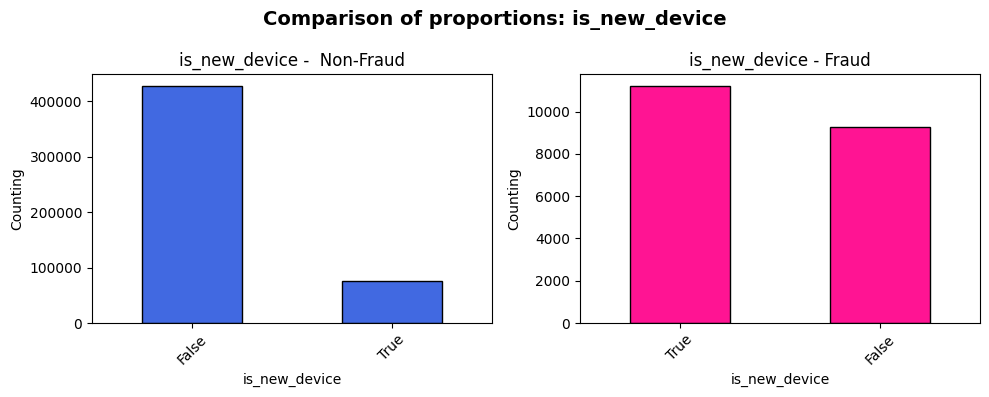

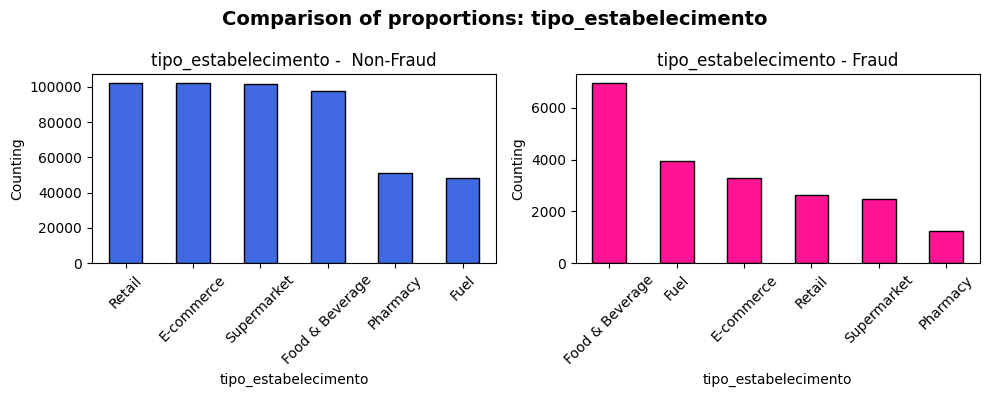

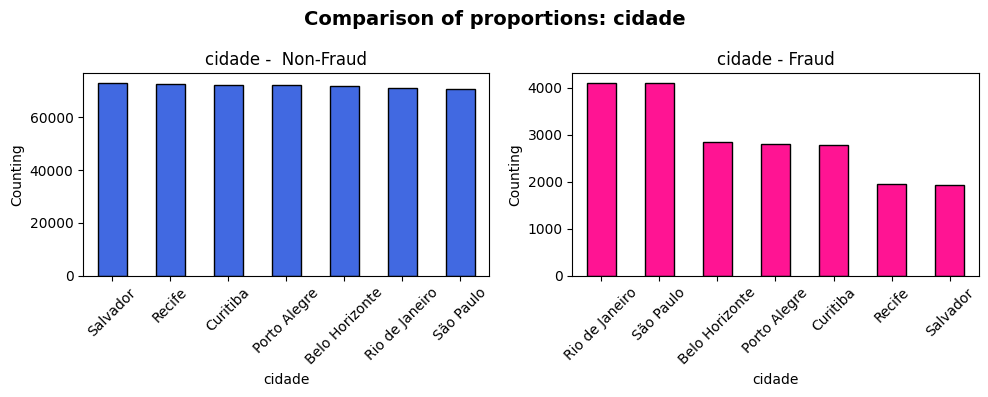

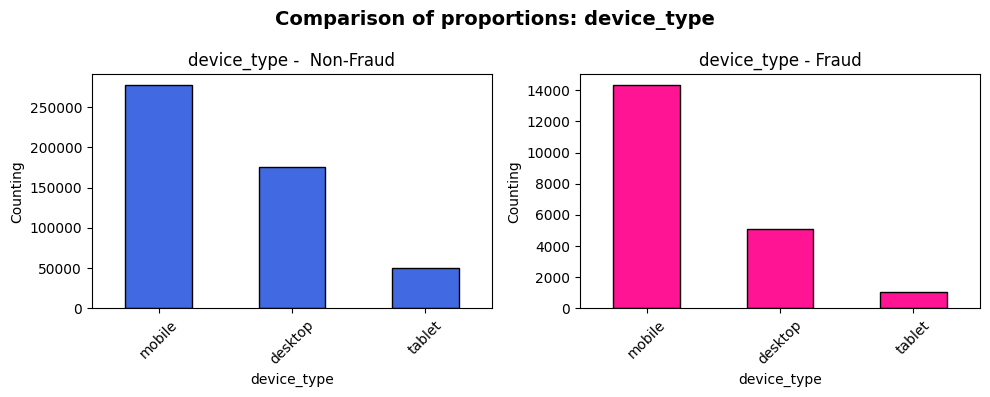

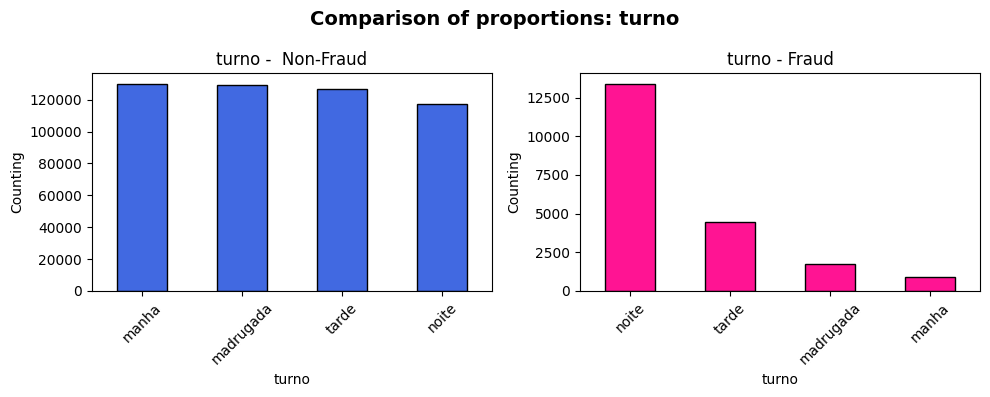

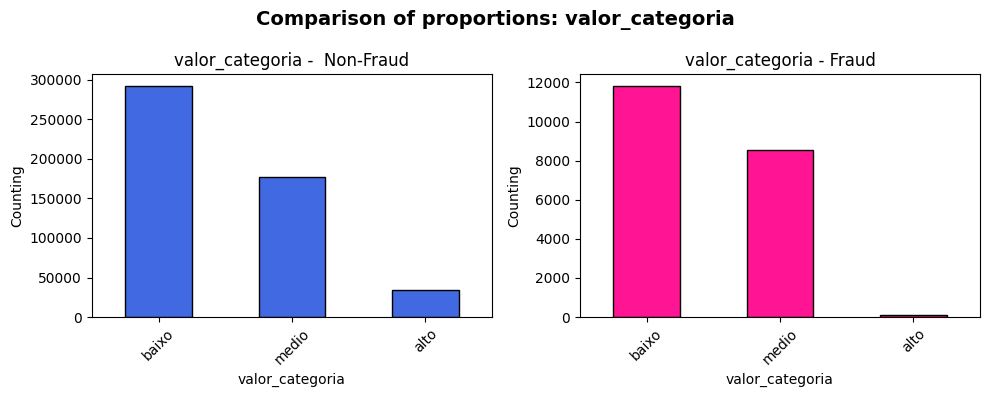

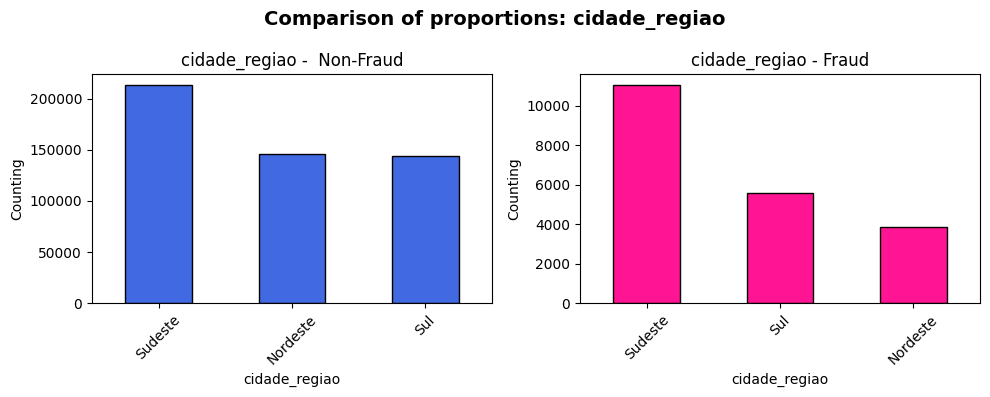

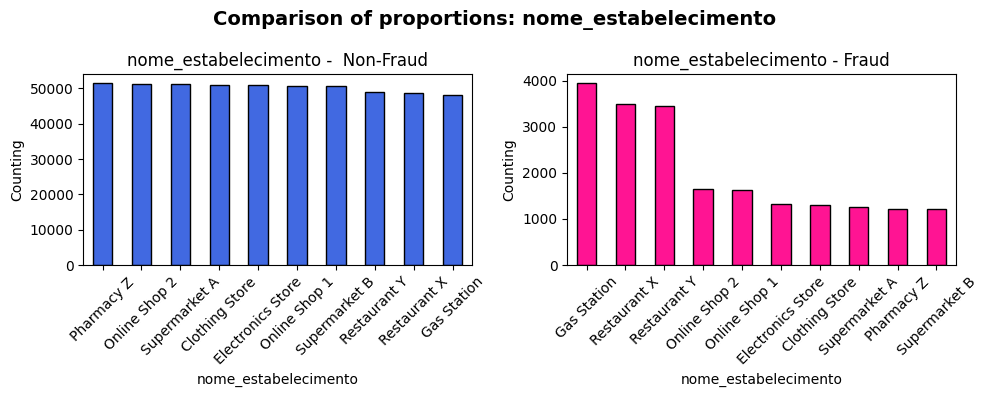

In [7]:
# Plotting the barcharts for categorical columns
# ---------------------------------------

categorical_columns = [
    'is_new_device', 'tipo_estabelecimento', 'cidade',
    'device_type', 'turno', 'valor_categoria', 'cidade_regiao', 'nome_estabelecimento'
]

for col in categorical_columns:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    df_historical[df_historical['flag_fraude'] == 0][col].value_counts().plot(
        kind='bar', ax=axes[0], color='royalblue', edgecolor='black'
    )
    axes[0].set_title(f'{col} -  Non-Fraud')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Counting')
    axes[0].tick_params(axis='x', rotation=45)

    df_historical[df_historical['flag_fraude'] == 1][col].value_counts().plot(
        kind='bar', ax=axes[1], color='deeppink', edgecolor='black'
    )
    axes[1].set_title(f'{col} - Fraud')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Counting')
    axes[1].tick_params(axis='x', rotation=45)

    plt.suptitle(f'Comparison of proportions: {col}', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()


The bar charts clearly show the difference in scale between the data labeled as “Fraud” and “Non-Fraud.” Some features have the same data distribution, such as “categoria_valor”, “device_type”, and “cidade_regiao”. 

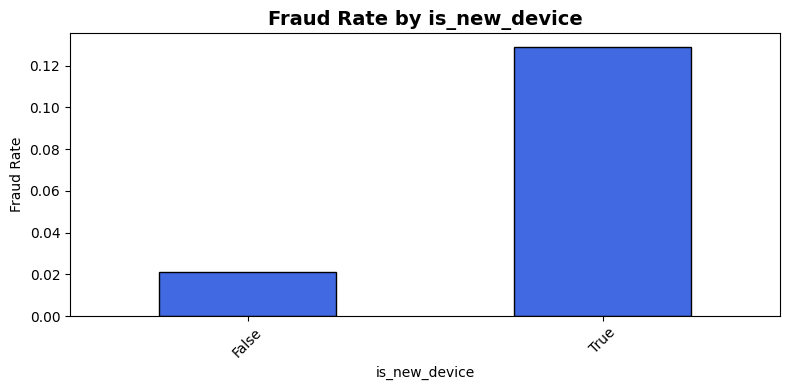

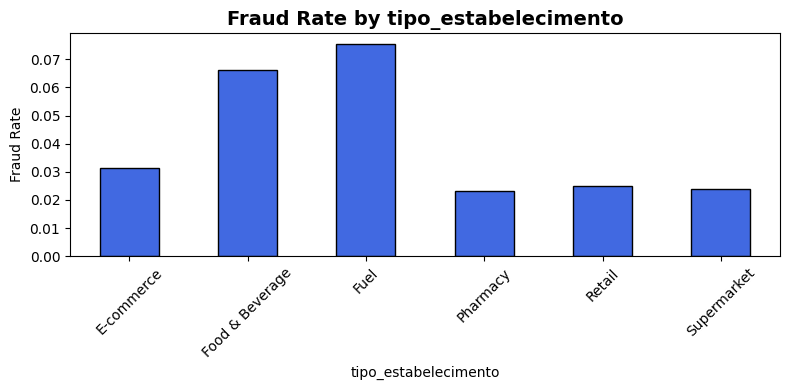

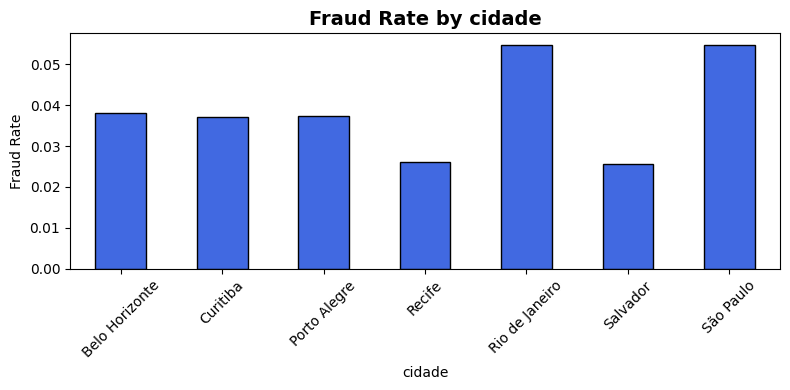

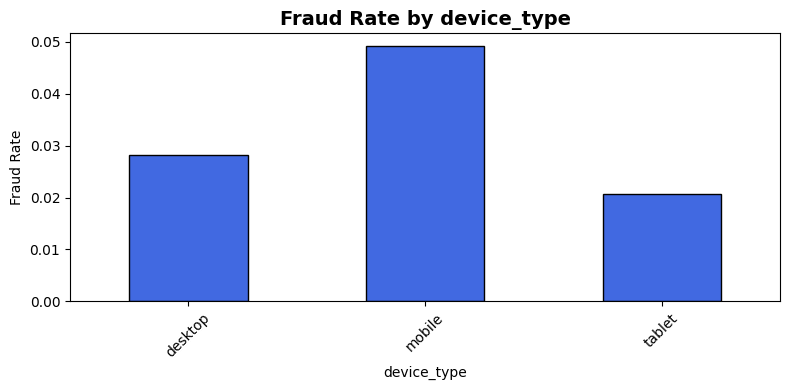

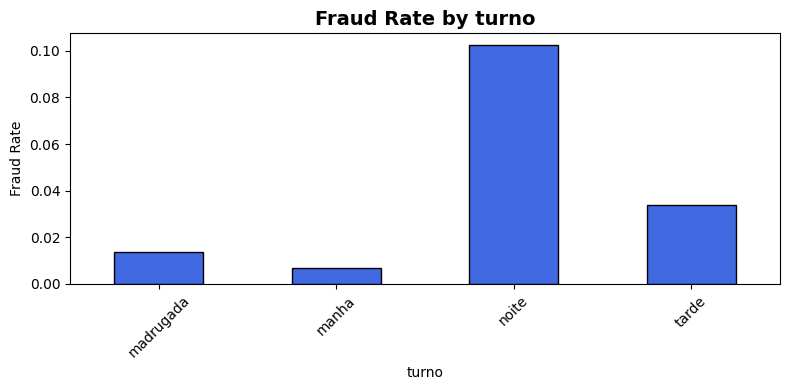

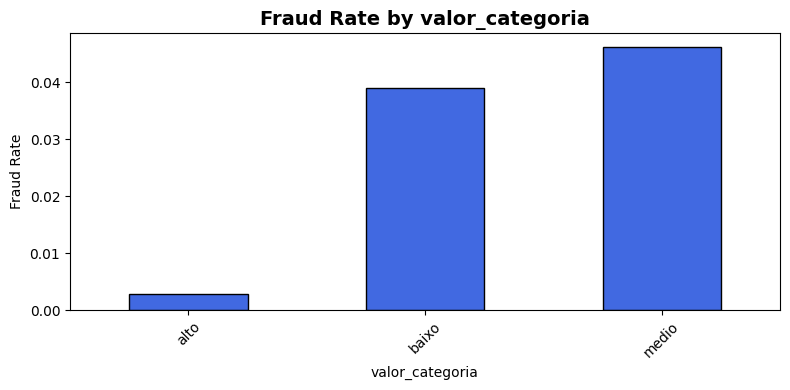

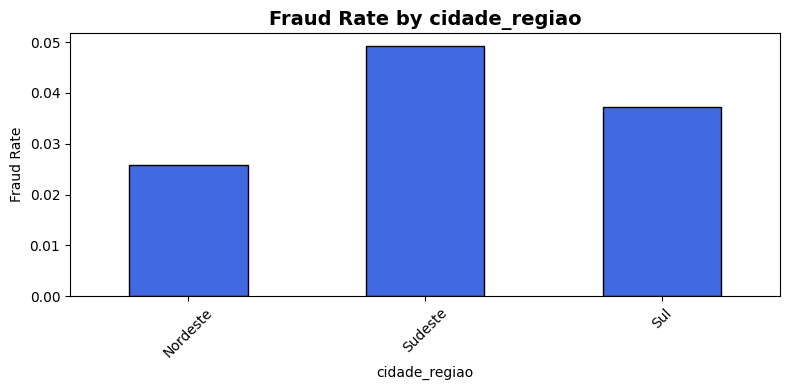

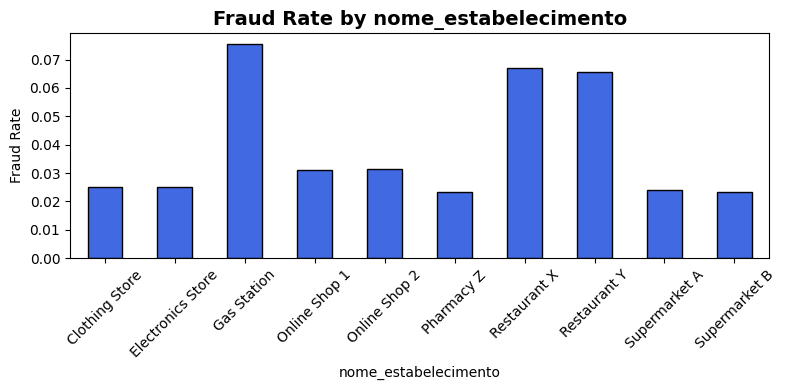

In [8]:
# plotting the fraud rate for each categorical column
# ---------------------------------------

for col in categorical_columns:
    fraud_rate = df_historical.groupby(col)['flag_fraude'].mean()

    plt.figure(figsize=(8, 4))
    fraud_rate.plot(kind='bar', color='royalblue', edgecolor='black')
    plt.title(f'Fraud Rate by {col}', fontsize=14, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Fraud Rate')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


Looking at the bar charts showing the fraud transaction rate, we can conclude that all features have labels associated with higher fraud rates. This can be observed, for example, in the cities of Rio de Janeiro and São Paulo under the “cidade” feature, “Mobile” under the “device_type” feature, “night” under the ‘turno’ feature, and “Gas Station,” “Restaurant X,” and “Restaurant Y” under the “nome_estabelecimento” feature. Therefore, using these features for training will help improve the model.

### Temporal and numerical analysis

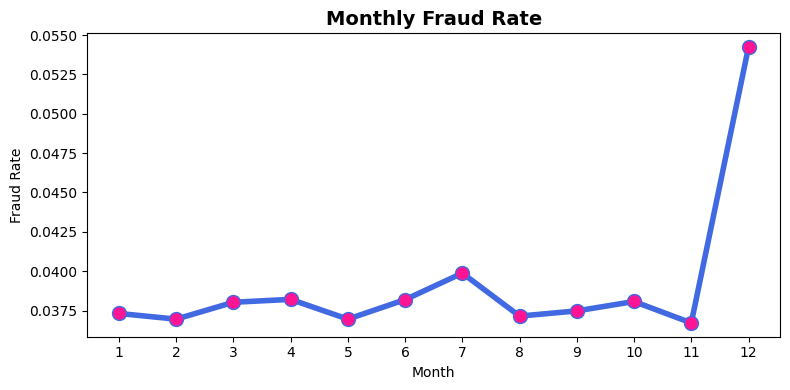

In [9]:
# Preparing dataset for monthly analysis
# ---------------------------------------
df_historical['month'] = df_historical['datahora_transacao'].dt.month
monthly = df_historical.groupby('month')['flag_fraude'].agg(['mean', 'sum', 'count'])
monthly = monthly.rename(columns={'mean': 'fraud_rate', 'sum': 'qtd_fraud', 'count': 'qtd_total'})

plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly['fraud_rate'], marker='o', color='royalblue', linestyle='-', linewidth=4, markersize=10, markerfacecolor='deeppink')
plt.title('Monthly Fraud Rate', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Fraud Rate')
plt.xticks(monthly.index)
plt.tight_layout()
plt.show()


By extracting the numerical month from the “datahora_transacao” feature and calculating the fraud rate, it is possible to observe certain seasonal patterns. In months considered “holiday months” (July, December), the number of fraud cases is higher.  

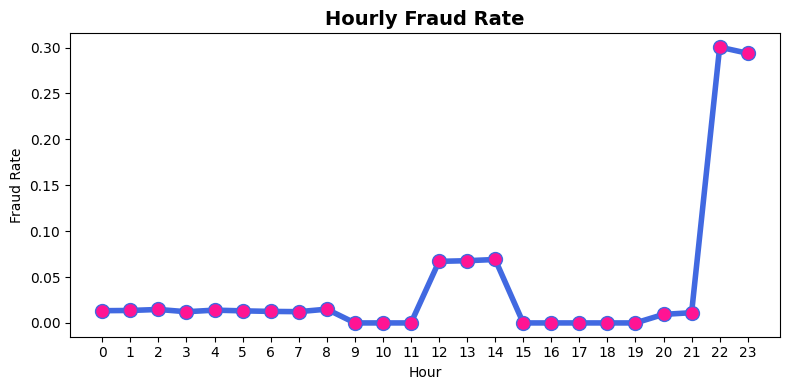

In [10]:
# Preparing dataset for hourly analysis
# ---------------------------------------
df_historical['hour'] = df_historical['datahora_transacao'].dt.hour
hourly = df_historical.groupby('hour')['flag_fraude'].agg(['mean', 'sum', 'count'])
hourly = hourly.rename(columns={'mean': 'fraud_rate', 'sum': 'qtd_fraud', 'count': 'qtd_total'})

plt.figure(figsize=(8, 4))
plt.plot(hourly.index, hourly['fraud_rate'], marker='o', color='royalblue', linestyle='-', linewidth=4, markersize=10, markerfacecolor='deeppink')
plt.title('Hourly Fraud Rate', fontsize=14, fontweight='bold')
plt.xlabel('Hour')
plt.ylabel('Fraud Rate')
plt.xticks(hourly.index)
plt.tight_layout()
plt.show()


Seasonal patterns can also be observed in the data broken down by hour of the day. There is a higher rate of fraud during “lunch” hours (12–14) and in the late afternoon.

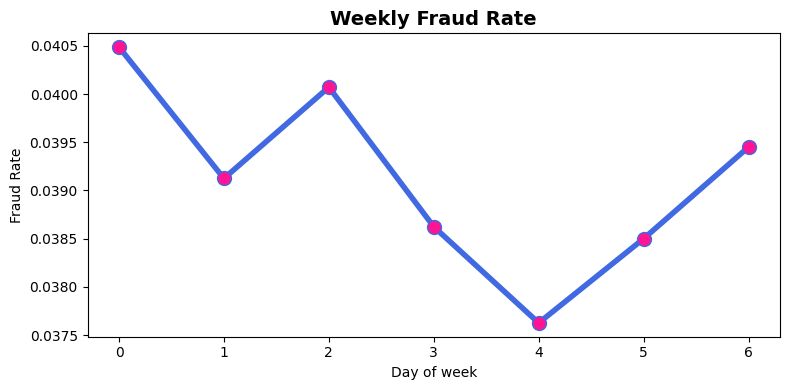

In [11]:
# Preparing dataset for daily analysis (day of the week and day of the month)
# ---------------------------------------
df_historical['day_of_week'] = df_historical['datahora_transacao'].dt.dayofweek

day_of_weekly = df_historical.groupby('day_of_week')['flag_fraude'].agg(['mean','sum','count'])
day_of_weekly = day_of_weekly.rename(columns={'mean': 'fraud_rate', 'sum': 'qtd_fraud', 'count': 'qtd_total'})

plt.figure(figsize=(8,4))
plt.plot(day_of_weekly.index, day_of_weekly['fraud_rate'], marker='o', color='royalblue', linestyle='-', linewidth=4, markersize=10, markerfacecolor='deeppink')
plt.title('Weekly Fraud Rate', fontsize=14, fontweight='bold')
plt.xlabel('Day of week')
plt.ylabel('Fraud Rate')
plt.xticks(day_of_weekly.index)
plt.tight_layout()
plt.show()


When we analyze the fraud rate by day of the week, we see that a lot of fraud occurs on the weekend. Despite this, there isn't a very clear pattern on the other days.

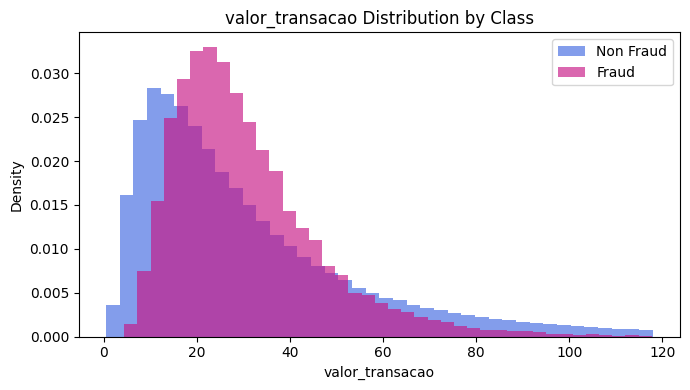

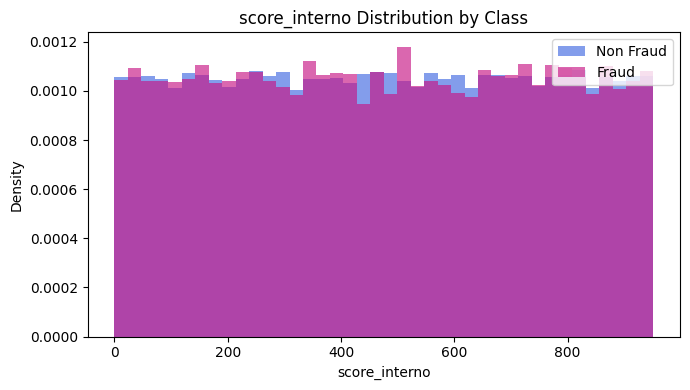

In [12]:
# List of numerical features
# ---------------------------------------
numeric_columns = ['valor_transacao', 'score_interno']

for col in numeric_columns:
    plt.figure(figsize=(7, 4))

    upper = df_historical[col].quantile(0.95)
    for target_value, label in [(0, 'Non Fraud'), (1, 'Fraud')]:
        subset = df_historical.loc[(df_historical['flag_fraude'] == target_value) & (df_historical[col] <= upper), col]
        plt.hist(subset, bins=40, alpha=0.65, density=True, label=label, color='royalblue' if target_value == 0 else 'mediumvioletred')
    plt.title(f'{col} Distribution by Class')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.legend()
    plt.tight_layout()
    plt.show()


For the retained numerical features, compare transaction amount (`valor_transacao`) and internal score (`score_interno`) across fraud classes. Temperature has been excluded from this analysis. Differences in these distributions are descriptive and do not establish incremental model value.


### Pairwise correlation analysis

Pearson correlations summarize pairwise linear associations. For binary indicators, these are point-biserial correlations with continuous variables. Small values do not rule out nonlinear relationships or interactions.

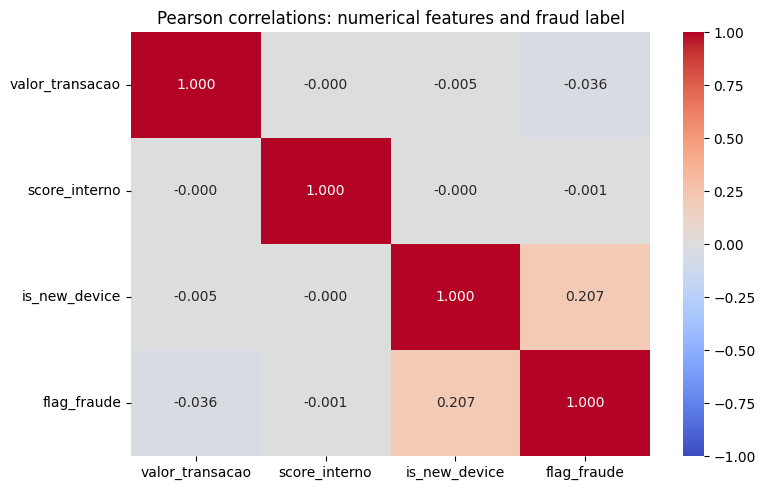

,valor_transacao,score_interno,is_new_device,flag_fraude
valor_transacao,1.000000,-0.000156,-0.005225,-0.035530
score_interno,-0.000156,1.000000,-0.000028,-0.000723
is_new_device,-0.005225,-0.000028,1.000000,0.206636
flag_fraude,-0.035530,-0.000723,0.206636,1.000000


In [13]:
# Calculate pairwise correlations among numerical features and the fraud label.
# ---------------------------------------
correlation_columns = [
    'valor_transacao', 'score_interno',
    'is_new_device', 'flag_fraude',
]
pearson_correlations = df_historical[correlation_columns].astype(float).corr()
plt.figure(figsize=(8, 5))
sns.heatmap(pearson_correlations, annot=True, fmt='.3f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0)
plt.title('Pearson correlations: numerical features and fraud label')
plt.tight_layout()
plt.show()
display(pearson_correlations)


### Canonical correlation analysis

Canonical correlation analysis (CCA) finds pairs of linear combinations with maximum correlation between two groups of variables. Here, the **numerical block** contains transaction amount and internal score. The **context block** contains cyclical encodings of hour, weekday, and month, plus device novelty. Sine/cosine pairs preserve the circular nature of time. Fraud labels, customer identifiers, and amount categories are excluded from both blocks.

A fixed sample of up to 50,000 complete transactions is split into 80% fitting and 20% held-out rows. Scaling and canonical directions are fitted only on the fitting partition. Two canonical pairs are evaluated on both partitions. Structure correlations describe how each original variable relates to its own block's canonical component; their signs can reverse together without changing the association.

This is exploratory linear association analysis, not a fraud classifier. The row-based holdout may contain the same customers as the fitting set and does not establish customer-independent or future-period generalization. No significance tests or causal claims are made. See the [scikit-learn CCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cross_decomposition.CCA.html).

**Reading the results:** `fit_correlation` measures association on the rows used to find the canonical combinations. `holdout_correlation` evaluates the same fixed combinations on separate rows. A large drop suggests that the fitting association does not reproduce on the held-out sample. These partitions belong only to this exploratory CCA and are separate from the fraud-model training workflow.


,canonical_pair,fit_correlation,holdout_correlation
0,1,0.018735,0.004489
1,2,0.013037,0.012646


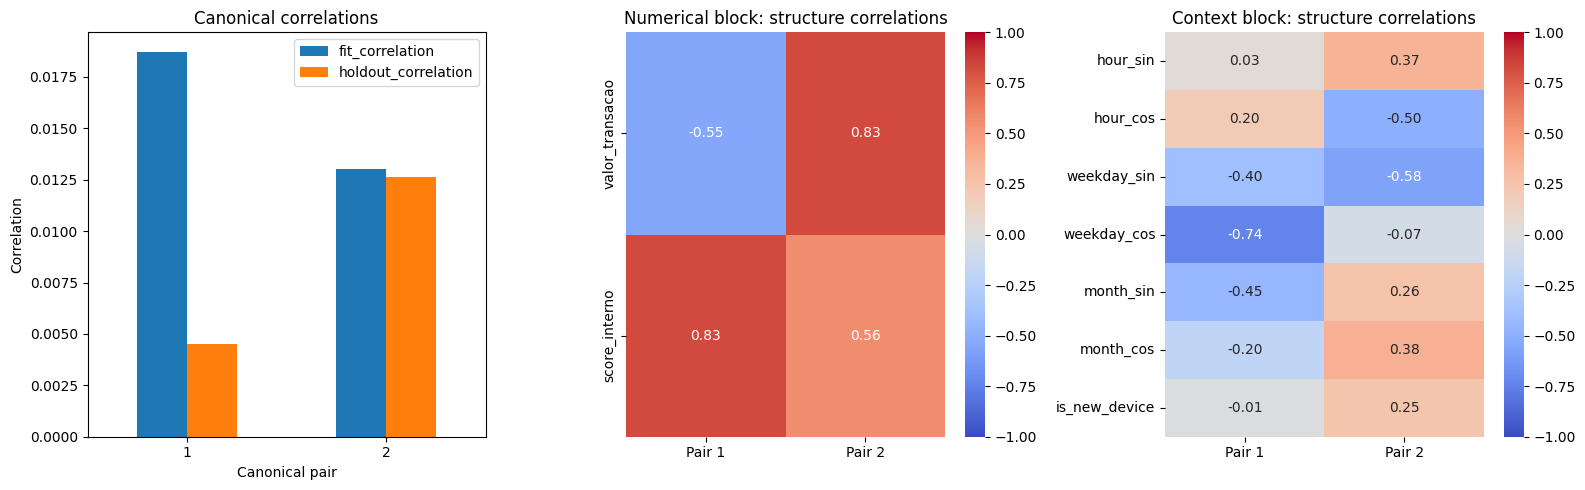

,Pair 1,Pair 2
valor_transacao,-0.552053,0.833809
score_interno,0.830323,0.557283


,Pair 1,Pair 2
hour_sin,0.031451,0.366564
hour_cos,0.199400,-0.502852
weekday_sin,-0.398295,-0.577375
weekday_cos,-0.740380,-0.070560
month_sin,-0.451413,0.260702
month_cos,-0.198824,0.379425
is_new_device,-0.012630,0.249427


In [ ]:
# Fit canonical correlation analysis and assess the associations on held-out rows.
# ---------------------------------------
# Keep the blocks separate: no target, identifiers, or amount-derived categories.
cca_numeric = df_historical[
    ['valor_transacao', 'score_interno']
].astype(float)
cca_time = df_historical['datahora_transacao']
cca_context = pd.DataFrame({
    'hour_sin': np.sin(2 * np.pi * cca_time.dt.hour / 24),
    'hour_cos': np.cos(2 * np.pi * cca_time.dt.hour / 24),
    'weekday_sin': np.sin(2 * np.pi * cca_time.dt.dayofweek / 7),
    'weekday_cos': np.cos(2 * np.pi * cca_time.dt.dayofweek / 7),
    'month_sin': np.sin(2 * np.pi * (cca_time.dt.month - 1) / 12),
    'month_cos': np.cos(2 * np.pi * (cca_time.dt.month - 1) / 12),
    'is_new_device': df_historical['is_new_device'].astype(float),
}, index=df_historical.index)

# Use a fixed sample for reproducible exploratory computation and exclude missing rows.
# ---------------------------------------

cca_complete = pd.concat([cca_numeric, cca_context], axis=1).replace(
    [np.inf, -np.inf], np.nan
).dropna()
cca_sample = cca_complete.sample(n=min(50000, len(cca_complete)), random_state=42)
cca_fit, cca_holdout = train_test_split(cca_sample, test_size=0.20, random_state=42)
cca_x_columns = list(cca_numeric.columns)
cca_y_columns = list(cca_context.columns)

# Fit centering, scaling, and canonical directions on the fitting partition only.
cca_model = CCA(n_components=2, scale=True, max_iter=2000, tol=1e-08)
cca_fit_x, cca_fit_y = cca_model.fit_transform(
    cca_fit[cca_x_columns], cca_fit[cca_y_columns]
)
cca_holdout_x, cca_holdout_y = cca_model.transform(
    cca_holdout[cca_x_columns], cca_holdout[cca_y_columns]
)
cca_results = pd.DataFrame({
    'canonical_pair': [1, 2],
    'fit_correlation': [np.corrcoef(cca_fit_x[:, k], cca_fit_y[:, k])[0, 1]
                        for k in range(2)],
    'holdout_correlation': [np.corrcoef(cca_holdout_x[:, k], cca_holdout_y[:, k])[0, 1]
                            for k in range(2)],
})
display(cca_results)

# Interpret components through within-block structure correlations, not raw weights.
# ---------------------------------------

cca_x_loadings = pd.DataFrame(
    np.corrcoef(cca_fit[cca_x_columns].to_numpy().T, cca_fit_x.T)[:2, 2:],
    index=cca_x_columns, columns=['Pair 1', 'Pair 2'],
)
cca_y_loadings = pd.DataFrame(
    np.corrcoef(cca_fit[cca_y_columns].to_numpy().T, cca_fit_y.T)[:7, 7:],
    index=cca_y_columns, columns=['Pair 1', 'Pair 2'],
)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
cca_results.set_index('canonical_pair').plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Canonical correlations', xlabel='Canonical pair', ylabel='Correlation')
sns.heatmap(cca_x_loadings, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, ax=axes[1])
axes[1].set_title('Numerical block: structure correlations')
sns.heatmap(cca_y_loadings, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, ax=axes[2])
axes[2].set_title('Context block: structure correlations')
fig.tight_layout()
plt.show()
display(cca_x_loadings, cca_y_loadings)


### Interpretation of the canonical correlation results

#### What is being compared?

This analysis asks whether transaction amount and internal score tend to vary together with transaction timing and device novelty. The numerical block contains `valor_transacao` and `score_interno`. The context block contains sine/cosine encodings of hour, weekday, and month, plus `is_new_device`. Temperature is excluded. The fraud label is also excluded: this analysis examines relationships between groups of input variables, not their ability to predict fraud.

CCA creates a score for every transaction by combining the variables within each block. These scores are synthetic coordinates, not original dataset columns or fraud probabilities. The variables are centered and scaled using only the fitting rows, so differences in measurement units do not by themselves determine the combinations.

#### What do Numerical 1, Context 1, Numerical 2, and Context 2 mean?

**Numerical 1** is the first weighted combination of standardized transaction amount and internal score. **Context 1** is the corresponding weighted combination of the standardized temporal encodings and device novelty. CCA chooses these two combinations to maximize their correlation on the fitting sample. The number 1 identifies the first canonical pair; it does not identify a customer, class, month, or original feature.

**Numerical 2** and **Context 2** are the second pair of combinations. They explore another direction of association after the first pair has been extracted. Context 2 is paired with Numerical 2, not with Numerical 1. There are only two pairs because the smaller block contains two variables.

Conceptually, each numerical score has the form `a × standardized amount + b × standardized internal score`. Each context score combines seven standardized inputs with its own fitted coefficients. The coefficients differ between pairs. A transaction therefore has four canonical scores, describing its position along these learned directions. A large positive score means a position along that component's chosen direction; it does not mean high fraud risk. The signs of both scores in a pair may be reversed together without changing their correlation or substantive interpretation.

#### Why compare fit_correlation and holdout_correlation?

The fixed sample contains **50,000 transactions**, split into **40,000 fitting rows** and **10,000 held-out rows**. CCA learns the scaling parameters and combinations only on the fitting rows. `fit_correlation` is the correlation between the two canonical scores on those same rows. Because the combinations were chosen to maximize fitting association, that value can be optimistic.

`holdout_correlation` applies the already fitted combinations to the separate rows and calculates their correlation without refitting. It checks whether the observed association carries over to another sample. These partitions belong to the exploratory CCA; they are separate from the fraud models' training, validation, and test partitions.

| Canonical pair | Scores compared | Fitting correlation | Held-out correlation |
| --- | --- | --- | --- |
| 1 | Numerical 1 and Context 1 | 0.0187 | 0.0045 |
| 2 | Numerical 2 and Context 2 | 0.0130 | 0.0126 |

Both fitting correlations are already close to zero. The first pair falls from 0.0187 to 0.0045 on the held-out rows, so even its small fitting association does not carry over at the same magnitude. The second pair is more similar across partitions, but a reproducible correlation near 0.013 is still very small. Stability and strength are different properties: an association can be consistently weak. Pairs are ordered by fitting correlation, so the second pair can have the larger held-out correlation.

These values describe little linear alignment between the chosen blocks in this sample. They do not show that fraud prediction is poor, because fraud labels did not enter this calculation. A correlation of 0.0126 is not 1.26% prediction accuracy or a fraud probability.

#### How should the structure correlations be interpreted?

The structure-correlation heatmaps compare each original variable with the canonical score from its own block. For the first pair, `score_interno` has a structure correlation of approximately **0.83** with Numerical 1, while `valor_transacao` has approximately **−0.55**. Numerical 1 therefore mainly contrasts higher internal scores with higher transaction amounts in the fitted sample. These are correlations with the component, not the coefficients of its formula.

In the context block, `weekday_cos` has the largest absolute first-pair structure correlation, approximately **−0.74**. This means Context 1 reflects a particular direction in the cyclical weekday representation. It does not establish that a specific weekday causes fraud or that weekday alone predicts it. Sine and cosine should be interpreted together when describing a calendar pattern. The first-pair loading for device novelty is close to zero (**−0.01**).

A variable can correlate strongly with its own component while the two components barely correlate with each other. Thus, the loadings of 0.83 and −0.74 do not contradict the very small correlation between Numerical 1 and Context 1. The heatmaps describe the composition of each side; the canonical-correlation table measures the relationship between the sides.

#### How do the pair plots help?

The original-feature pair plot shows distributions, extreme transaction amounts, and pairwise relationships, with fraud labels used only for color. Because fraud is uncommon, its points can be visually underrepresented. The device indicator produces bands because it is binary. The plot uses up to 5,000 randomly selected rows without balancing the classes or removing amount outliers.

The canonical-score pair plot uses up to 3,000 held-out rows. The relevant matched panels are **Numerical 1 versus Context 1** and **Numerical 2 versus Context 2**. A strong linear association would tend to produce a sloping, elongated cloud; the measured correlations here indicate little overall linear alignment. Discrete temporal/device inputs may create bands. Other panels show cross-pair or within-block relationships and should not be read as the corresponding canonical correlations. The numerical table uses all 10,000 held-out rows and is the reference for association strength.

#### How can these results help the project?

First, they check a concrete exploratory hypothesis: whether amount and internal score share substantial linear structure with transaction timing and device novelty. The current result provides little support for that hypothesis under these encodings and this sampling design. This avoids claiming that these groups move strongly together when the measured associations are very small.

Second, they help distinguish component composition from useful cross-block association. Large loadings alone are not a reason to select features or add canonical scores to the fraud model. With these weak held-out correlations, this analysis provides little motivation to introduce these particular CCA components merely to capture shared linear variation. Any proposed use of the scores would still require fitting CCA only within the model's training partition and evaluating its incremental value on validation data.

Third, they guide the next questions. A lack of linear alignment between blocks does not imply independence and does not rule out nonlinear effects or fraud-related interactions. A high amount on a new device, for example, could be relevant to fraud even if amount and device novelty have little overall correlation. Such hypotheses should be evaluated with validation-based comparisons of the existing models, grouped permutation importance, or feature ablations, using average precision and fraud recovery under the review budget.

No feature should be discarded solely because of these results, and no model configuration is changed here. A random row split can contain the same customers in both partitions; it does not establish performance on unseen customers or future periods. Repeated transactions, sampling variability, extreme amounts, and the chosen linear encodings also limit interpretation. No significance tests or causal claims are made.


### Pair plots of the retained features and canonical scores

The first pair plot shows transaction amount, internal score, and device novelty, colored by fraud label. A fixed random sample of up to 5,000 rows preserves the observed class proportions approximately; fraud is uncommon and may be visually underrepresented. Binary device novelty produces bands rather than a continuous cloud. The plot uses original amounts without clipping outliers.

The second pair plot shows the two pairs of canonical scores on up to 3,000 held-out rows. Compare `Numerical 1` with `Context 1` and `Numerical 2` with `Context 2` to visualize the corresponding canonical associations. The other panels are cross-component comparisons. Fraud labels are used only to color the first plot, never to fit CCA.


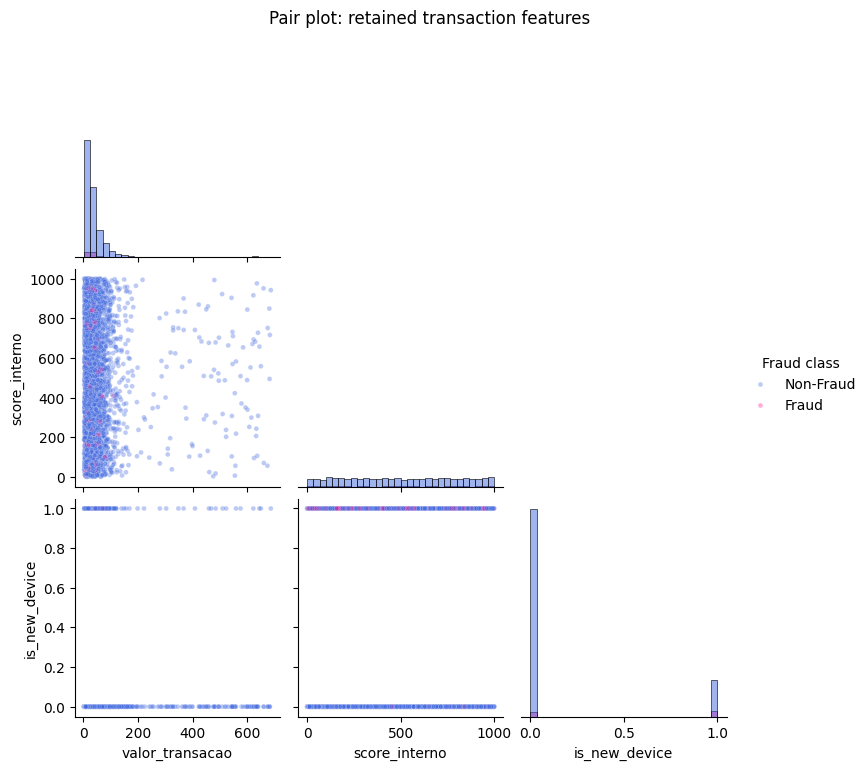

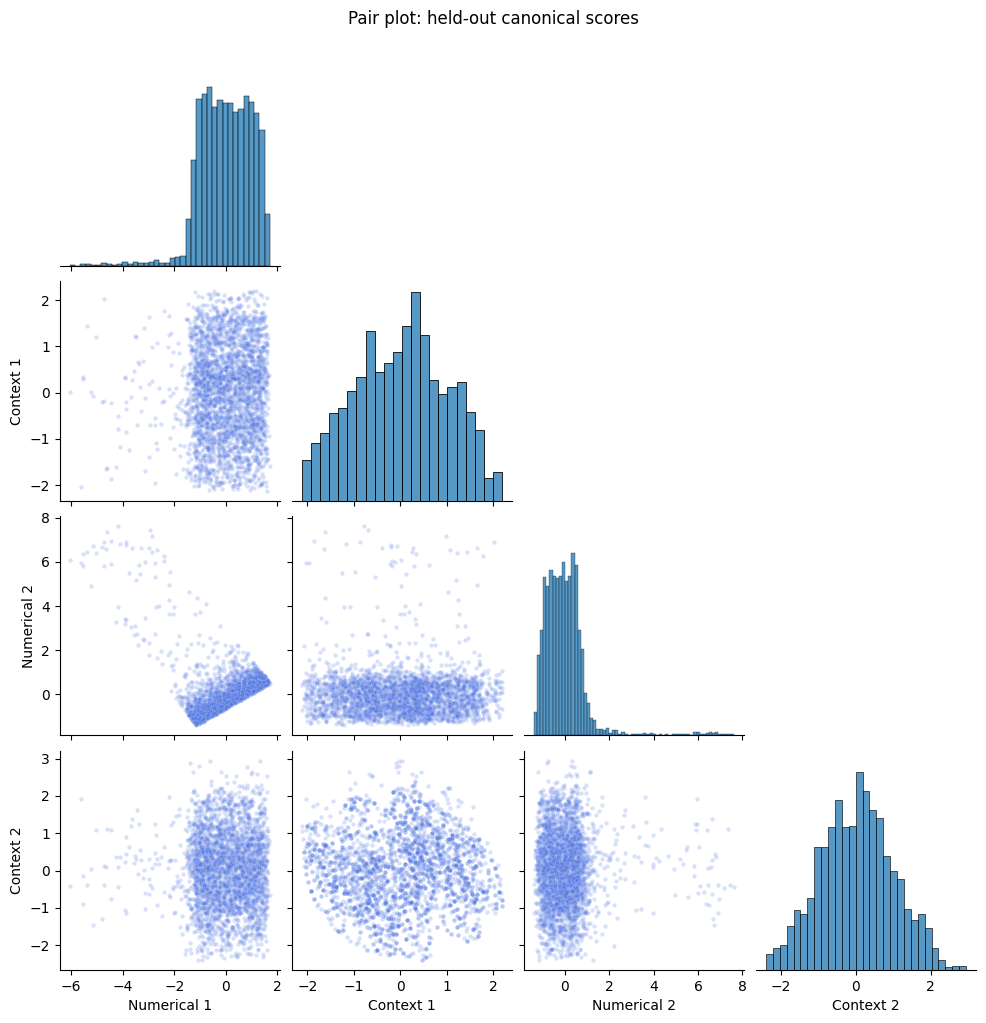

In [ ]:
# Visualize pairwise feature relationships and held-out canonical score pairs.
# ---------------------------------------
# Sample original variables without balancing or changing the observed class distribution.
pairplot_data = df_historical[
    ['valor_transacao', 'score_interno', 'is_new_device', 'flag_fraude']
].dropna().sample(n=min(5000, len(df_historical.dropna(subset=[
    'valor_transacao', 'score_interno', 'is_new_device', 'flag_fraude'
]))), random_state=42).copy()
pairplot_data['is_new_device'] = pairplot_data['is_new_device'].astype(int)
pairplot_data['Fraud class'] = pairplot_data['flag_fraude'].astype(int).map({0: 'Non-Fraud', 1: 'Fraud'})
feature_pairs = sns.pairplot(
    pairplot_data, vars=['valor_transacao', 'score_interno', 'is_new_device'],
    hue='Fraud class', hue_order=['Non-Fraud', 'Fraud'],
    palette={'Non-Fraud': 'royalblue', 'Fraud': 'deeppink'},
    diag_kind='hist', corner=True,
    plot_kws={'alpha': 0.35, 's': 12}, diag_kws={'bins': 30},
)
feature_pairs.fig.suptitle('Pair plot: retained transaction features', y=1.02)
plt.show()

# Plot fixed canonical projections of rows that were not used to fit CCA.
# ---------------------------------------

canonical_pairplot_data = pd.DataFrame({
    'Numerical 1': cca_holdout_x[:, 0], 'Context 1': cca_holdout_y[:, 0],
    'Numerical 2': cca_holdout_x[:, 1], 'Context 2': cca_holdout_y[:, 1],
}).sample(n=min(3000, len(cca_holdout_x)), random_state=42)
canonical_pairs = sns.pairplot(
    canonical_pairplot_data, diag_kind='hist', corner=True,
    plot_kws={'alpha': 0.20, 's': 10, 'color': 'royalblue'},
)
canonical_pairs.fig.suptitle('Pair plot: held-out canonical scores', y=1.02)
plt.show()


## Multivariate analysis: combined signals and monthly stability

The analyses below examine risk hypotheses alongside the support of each segment. Rates are accompanied by transaction counts and 95% Wilson intervals; cells with fewer than 100 purchases are hidden in the rate chart. These intervals are descriptive binomial approximations: they do not account for repeated purchases by the same customer or multiple comparisons.

The questions are: does a new device have the same association with fraud across time periods and cities? Does the effect of transaction amount depend on the establishment? Do patterns persist across months or reflect changes in the dataset composition? The conclusions below are computed from the data without assuming the results.


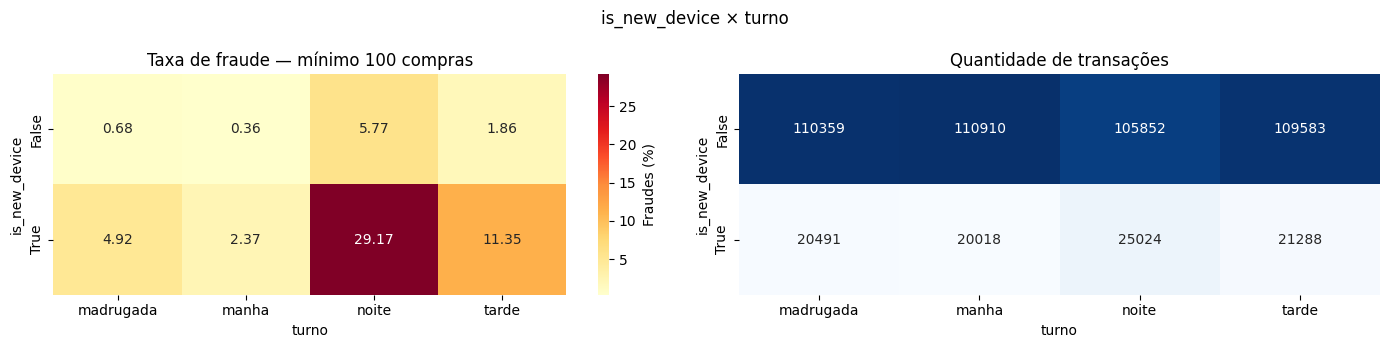

**Leitura descritiva:** maior taxa elegível em is_new_device=True, turno=noite: **29.17%**, 7,300 fraudes em 25,024 compras (IC 95%: 28.61%–29.74%; lift 7.46× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

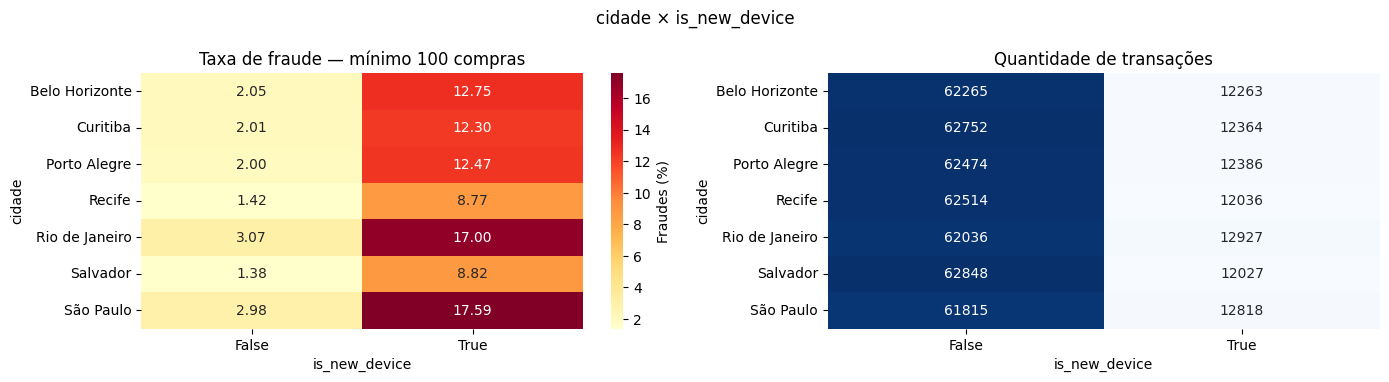

**Leitura descritiva:** maior taxa elegível em cidade=São Paulo, is_new_device=True: **17.59%**, 2,255 fraudes em 12,818 compras (IC 95%: 16.94%–18.26%; lift 4.50× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

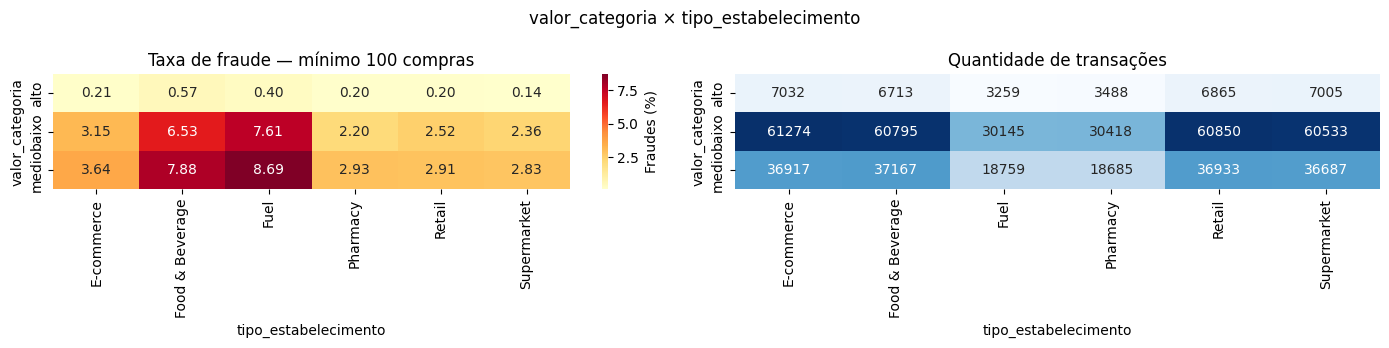

**Leitura descritiva:** maior taxa elegível em valor_categoria=medio, tipo_estabelecimento=Fuel: **8.69%**, 1,630 fraudes em 18,759 compras (IC 95%: 8.29%–9.10%; lift 2.22× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

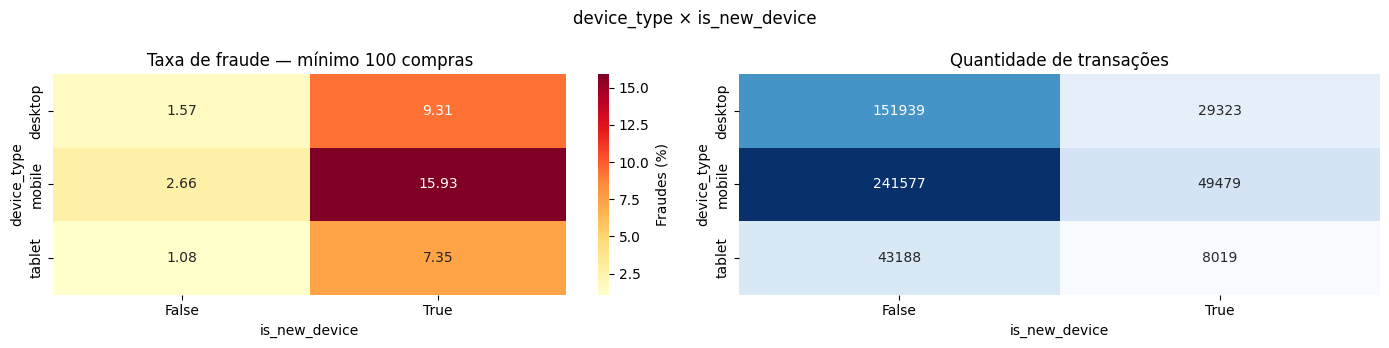

**Leitura descritiva:** maior taxa elegível em device_type=mobile, is_new_device=True: **15.93%**, 7,880 fraudes em 49,479 compras (IC 95%: 15.61%–16.25%; lift 4.07× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

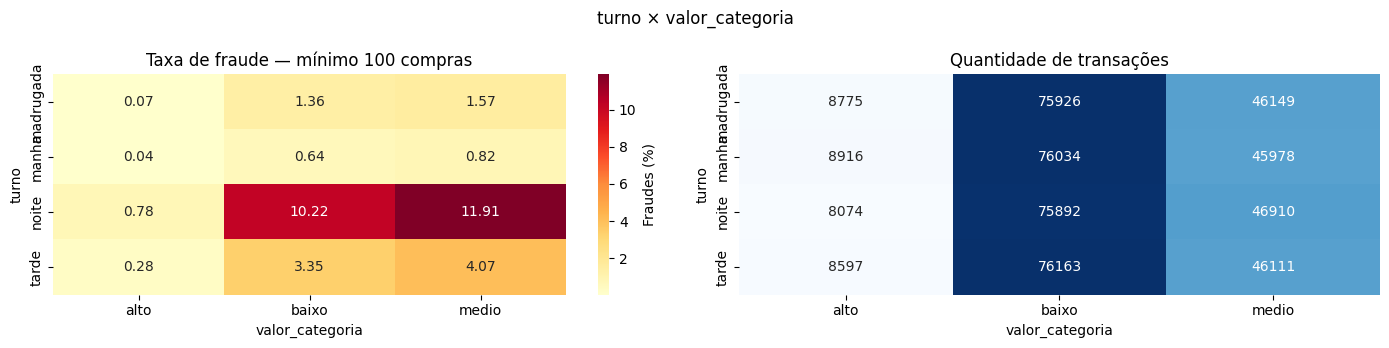

**Leitura descritiva:** maior taxa elegível em turno=noite, valor_categoria=medio: **11.91%**, 5,585 fraudes em 46,910 compras (IC 95%: 11.62%–12.20%; lift 3.04× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

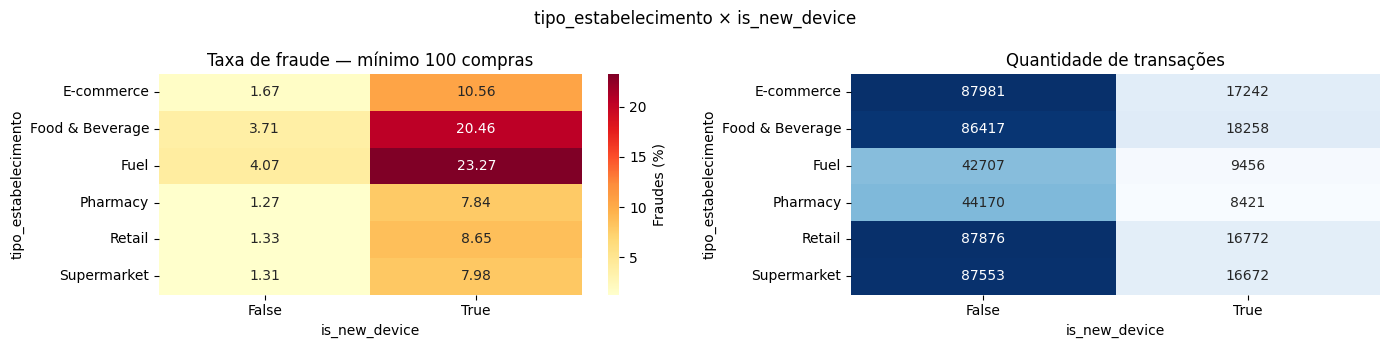

**Leitura descritiva:** maior taxa elegível em tipo_estabelecimento=Fuel, is_new_device=True: **23.27%**, 2,200 fraudes em 9,456 compras (IC 95%: 22.42%–24.13%; lift 5.95× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

In [16]:
# Compare fraud rates and transaction counts across categorical feature pairs.
# ---------------------------------------
cruzamentos_eda = {}
for linha, coluna in [
    ('is_new_device', 'turno'),
    ('cidade', 'is_new_device'),
    ('valor_categoria', 'tipo_estabelecimento'),
    ('device_type', 'is_new_device'),
    ('turno', 'valor_categoria'),
    ('tipo_estabelecimento', 'is_new_device'),
]:
    cruzamentos_eda[(linha, coluna)] = plot_cross(df_historical, linha, coluna)


### Conditional relationships: amount and time period within establishment type

The next comparison adds a third dimension. It checks whether an association observed in the full dataset also appears within each establishment type. Differences between groups remain descriptive associations and should not be interpreted as causal.


Establishment type: E-commerce


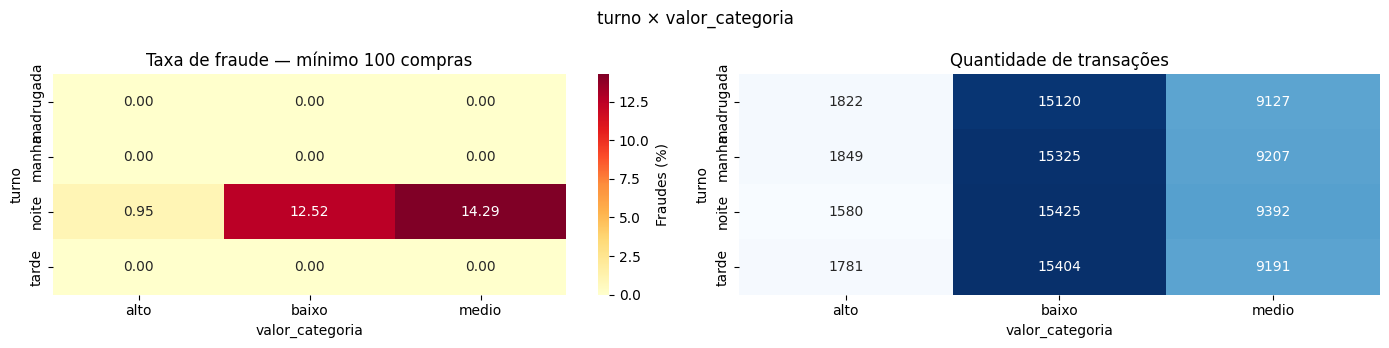

**Leitura descritiva:** maior taxa elegível em turno=noite, valor_categoria=medio: **14.29%**, 1,342 fraudes em 9,392 compras (IC 95%: 13.60%–15.01%; lift 4.57× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

Establishment type: Food & Beverage


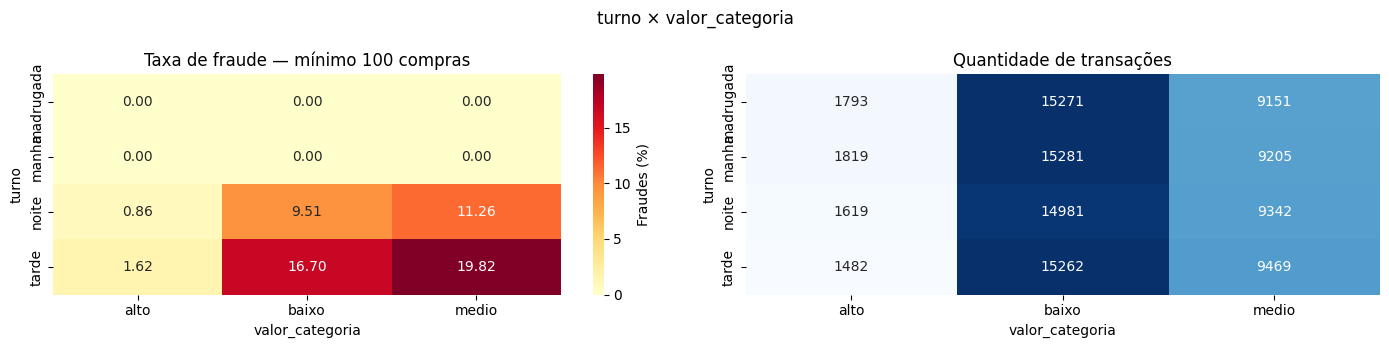

**Leitura descritiva:** maior taxa elegível em turno=tarde, valor_categoria=medio: **19.82%**, 1,877 fraudes em 9,469 compras (IC 95%: 19.03%–20.64%; lift 2.99× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

Establishment type: Fuel


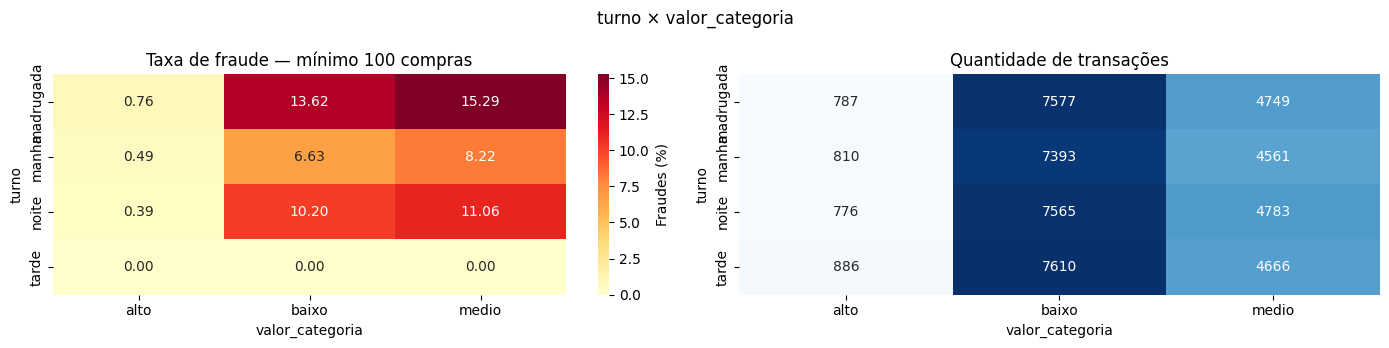

**Leitura descritiva:** maior taxa elegível em turno=madrugada, valor_categoria=medio: **15.29%**, 726 fraudes em 4,749 compras (IC 95%: 14.29%–16.34%; lift 2.03× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

Establishment type: Pharmacy


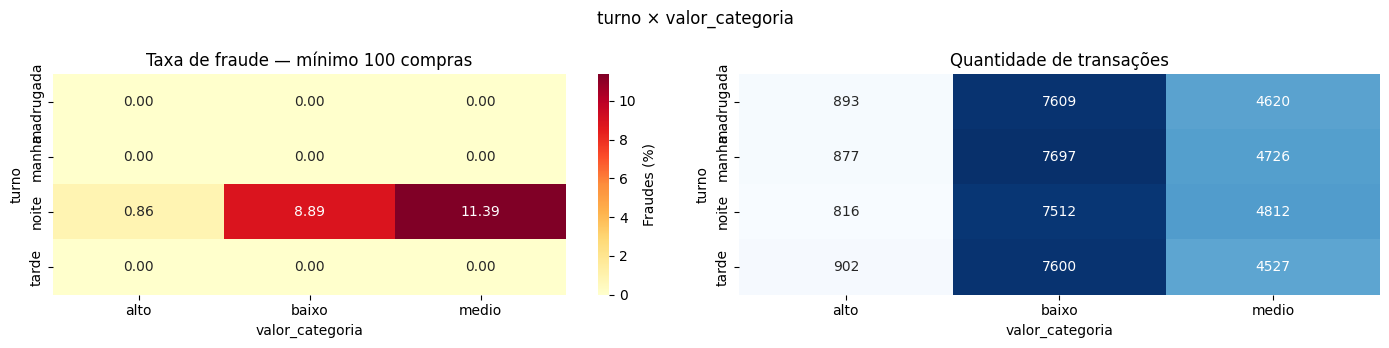

**Leitura descritiva:** maior taxa elegível em turno=noite, valor_categoria=medio: **11.39%**, 548 fraudes em 4,812 compras (IC 95%: 10.52%–12.32%; lift 4.90× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

Establishment type: Retail


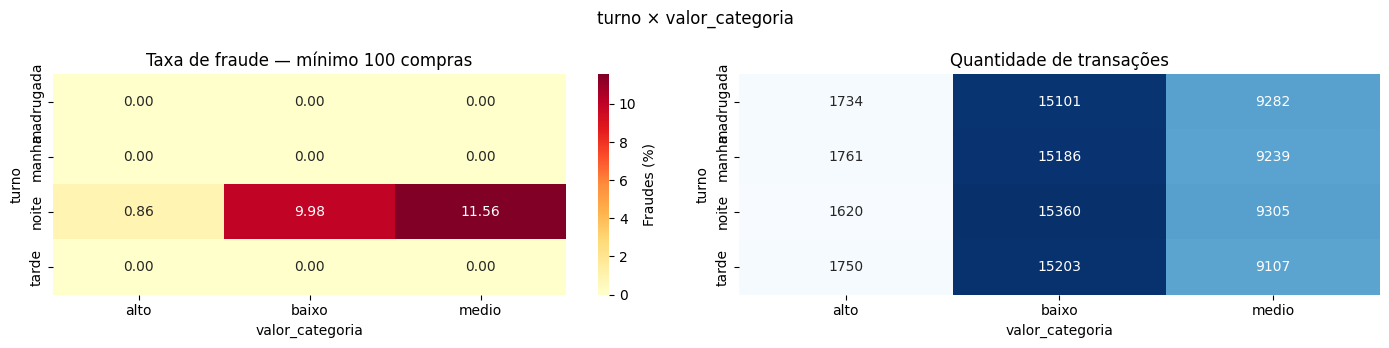

**Leitura descritiva:** maior taxa elegível em turno=noite, valor_categoria=medio: **11.56%**, 1,076 fraudes em 9,305 compras (IC 95%: 10.93%–12.23%; lift 4.61× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

Establishment type: Supermarket


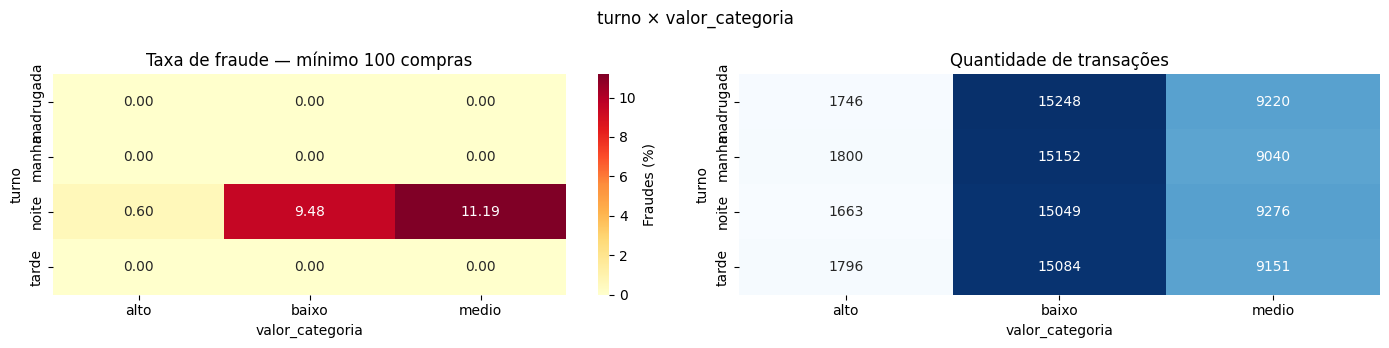

**Leitura descritiva:** maior taxa elegível em turno=noite, valor_categoria=medio: **11.19%**, 1,038 fraudes em 9,276 compras (IC 95%: 10.56%–11.85%; lift 4.71× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

In [17]:
# Compare time periods and amount categories within each establishment type.
# ---------------------------------------
cruzamentos_condicionais = {}
for estabelecimento, grupo in df_historical.groupby('tipo_estabelecimento', observed=True):
    print(f'Establishment type: {estabelecimento}')
    cruzamentos_condicionais[estabelecimento] = plot_cross(grupo, 'turno', 'valor_categoria')


### Monthly rates and segment composition

Fraud rate and share of transaction volume answer different questions. The charts show both to avoid attributing an aggregate change exclusively to individual risk. This section describes the actual labels; it does not measure model errors.


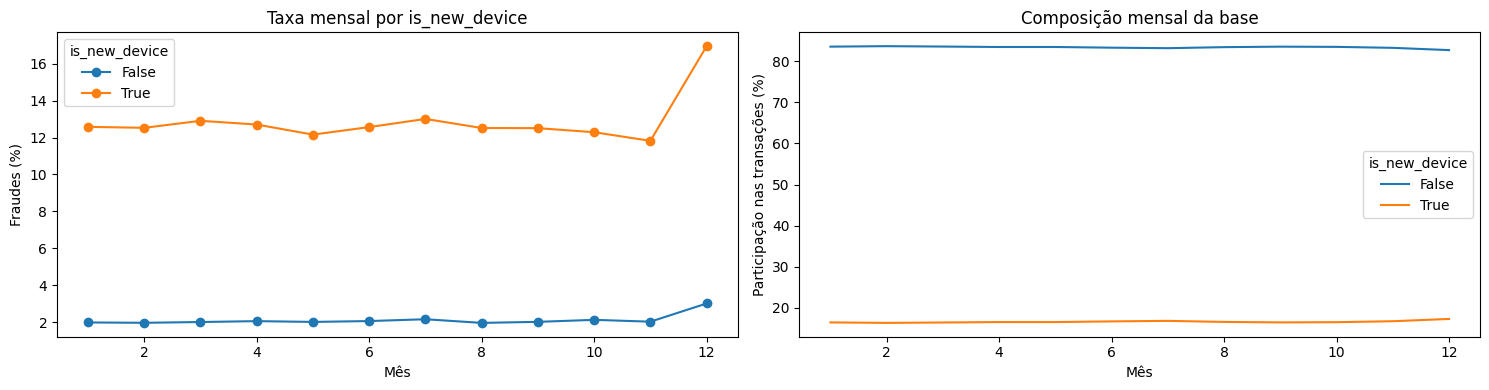

**Estabilidade por segmento:** a maior amplitude mensal observada foi 5.12 pontos percentuais (is_new_device=True). Compare a taxa dentro de cada grupo com sua participação no volume: uma mudança na taxa global pode acompanhar mudanças na composição. Um único ano não permite confirmar sazonalidade recorrente.

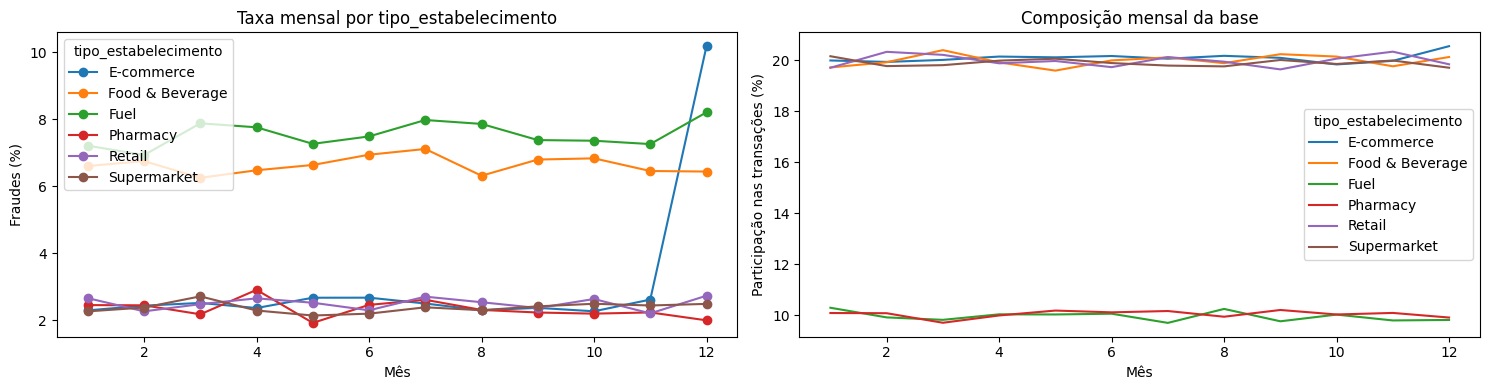

**Estabilidade por segmento:** a maior amplitude mensal observada foi 7.91 pontos percentuais (tipo_estabelecimento=E-commerce). Compare a taxa dentro de cada grupo com sua participação no volume: uma mudança na taxa global pode acompanhar mudanças na composição. Um único ano não permite confirmar sazonalidade recorrente.

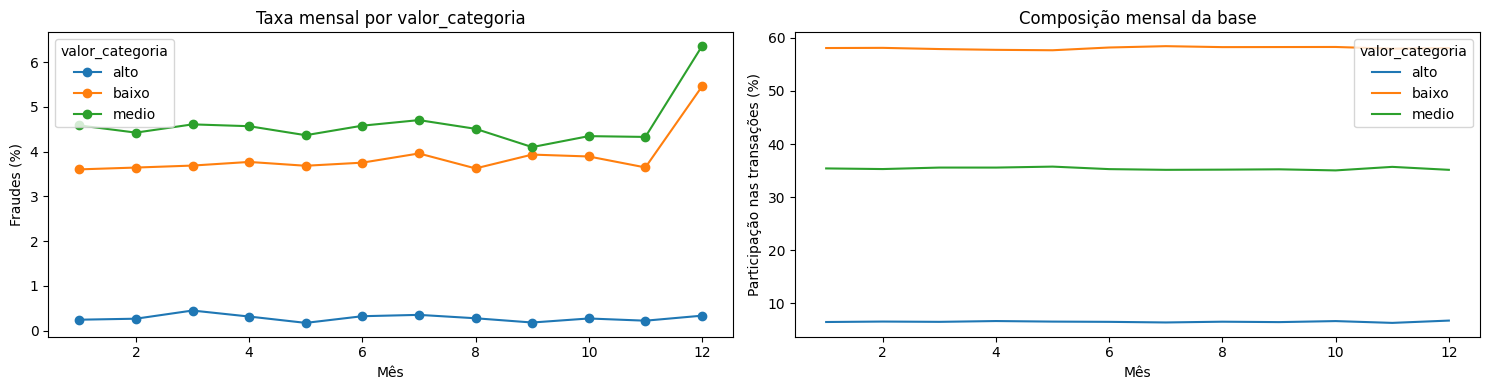

**Estabilidade por segmento:** a maior amplitude mensal observada foi 2.26 pontos percentuais (valor_categoria=medio). Compare a taxa dentro de cada grupo com sua participação no volume: uma mudança na taxa global pode acompanhar mudanças na composição. Um único ano não permite confirmar sazonalidade recorrente.

In [18]:
# Analyze monthly fraud rates and transaction shares by segment.
# ---------------------------------------
segmentos_mensais = {}
for segmento in ['is_new_device', 'tipo_estabelecimento', 'valor_categoria']:
    segmentos_mensais[segmento] = plot_month_segments(df_historical, segmento)


## Feature Engineering 

The data will now be reset so that the features can be created and/or transformed. The functions below define the feature engineering and preprocessing workflow. 

In [19]:
# Define the feature engineering and preprocessing functions.
# ---------------------------------------
def transform_dtypes(dataframe: pd.DataFrame,
                     feature_list: list,
                     making_predictions = True
    ) -> pd.DataFrame:

    """
    Function created to transform dtypes of every feature to assure correct workflow.

    Parameters
    ----------
        dataframe : pd.DataFrame
            Dataframe to have features created.

        feature_list : list
            List with initial features list to workflow.

        making_predictions : bool
            Boolean variable to decide whether the function will be used for predictions or not.
    Returns
        making_predictions : pd.DataFrame
            Dataframe with correct dtypes features
    -------
    """
    # Filtering features according to feature_list
    if making_predictions:
        feature_list_predictions = feature_list
        feature_list_predictions.remove('flag_fraude')

        dataframe = dataframe[feature_list_predictions]
    else:
        dataframe = dataframe[feature_list]

    # Temporal Features
    if 'datahora_transacao' in feature_list:
        dataframe['datahora_transacao'] = pd.to_datetime(dataframe['datahora_transacao'], format='%Y-%m-%d %H:%M:%S')

        return dataframe
    else:
        print(f"Used dataframe has no feature called datahora_transacao")


BEHAVIOR_NUMERICAL_FEATURES = [
    "compras_ultimas_24h", "compras_ultimos_7d", "compras_ultimos_30d",
    "horas_desde_ultima_compra", "valor_medio_ultimos_30d",
    "valor_desvio_padrao_ultimos_30d", "valor_diferenca_media_30d",
    "valor_razao_media_30d",
]


def create_behavior_features(
    dataframe: pd.DataFrame
) -> pd.DataFrame:
    """
    Create label-free customer history features from strictly earlier events.

    Parameters
    ----------
    dataframe : pd.DataFrame
        Transactions containing customer, timestamp, and amount columns.

    Returns
    -------
    result : pd.DataFrame
        Transactions with historical counts, intervals, and spending statistics.
        The original row order and index are preserved.

    Notes
    -----
    Windows include their left boundary and exclude the current timestamp.
    Missing means and intervals remain NaN. Sample standard deviation requires
    two earlier purchases. Ratios with a zero historical mean remain NaN.
    """
    result = dataframe.copy()
    history = dataframe[["nome_cliente", "datahora_transacao", "valor_transacao"]].copy()
    history.index = pd.RangeIndex(len(history))
    history = history.sort_values(["nome_cliente", "datahora_transacao"], kind="stable")
    groups = history.groupby("nome_cliente", sort=False, dropna=False)

    # Shift distinct timestamps so simultaneous purchases never see each other.
    distinct = history[["nome_cliente", "datahora_transacao"]].drop_duplicates().copy()
    distinct["previous_time"] = distinct.groupby(
        "nome_cliente", sort=False, dropna=False
    )["datahora_transacao"].shift()
    previous = history.reset_index().merge(
        distinct, on=["nome_cliente", "datahora_transacao"], how="left", validate="many_to_one"
    ).set_index("index").reindex(range(len(result)))
    result["horas_desde_ultima_compra"] = (
        (previous["datahora_transacao"] - previous["previous_time"])
        .dt.total_seconds().to_numpy() / 3600
    )
    result["sem_historico_anterior"] = previous["previous_time"].isna().to_numpy().astype(int)

    for window, name in [
        ("24h", "compras_ultimas_24h"),
        ("7D", "compras_ultimos_7d"),
        ("30D", "compras_ultimos_30d"),
    ]:
        rolling = groups.rolling(window, on="datahora_transacao", closed="left", min_periods=1)
        counts = rolling["valor_transacao"].count().reset_index(level=0, drop=True)
        result[name] = pd.Series(counts.to_numpy(), index=history.index).reindex(range(len(result))).fillna(0).to_numpy()
        if window == "30D":
            for statistic, column in [
                ("mean", "valor_medio_ultimos_30d"),
                ("std", "valor_desvio_padrao_ultimos_30d"),
            ]:
                values = getattr(rolling["valor_transacao"], statistic)()
                result[column] = pd.Series(values.to_numpy(), index=history.index).reindex(range(len(result))).to_numpy()

    result["valor_diferenca_media_30d"] = result["valor_transacao"] - result["valor_medio_ultimos_30d"]
    denominator = result["valor_medio_ultimos_30d"].replace(0, np.nan)
    result["valor_razao_media_30d"] = result["valor_transacao"] / denominator
    return result


MULTIVARIATE_NUMERICAL_FEATURES = ["novo_device_razao_valor_30d"]
MULTIVARIATE_FEATURES = [
    "novo_device_noite", "novo_device_mudanca_cidade",
    *MULTIVARIATE_NUMERICAL_FEATURES,
]


def create_multivariate_features(
    dataframe: pd.DataFrame
) -> pd.DataFrame:
    """
    Combine device novelty with time, city change, and relative spending.

    Parameters
    ----------
    dataframe : pd.DataFrame
        Transactions containing the device and behavioral features.

    Returns
    -------
    result : pd.DataFrame
        Transactions with binary and numerical interaction features.

    Notes
    -----
    No labels or fitted statistics are used. Missing historical ratios remain
    missing, including for known devices, so missing history is not zero.
    """
    result = dataframe.copy()
    new_device = result["is_new_device"].astype(bool)
    result["novo_device_noite"] = (
        new_device & result["turno"].eq("noite")
    ).astype(int)
    result["novo_device_mudanca_cidade"] = (
        new_device & result["changed_cidade"].eq(1)
    ).astype(int)
    result["novo_device_razao_valor_30d"] = (
        new_device.astype(int) * result["valor_razao_media_30d"]
    )
    return result


def create_features(dataframe: pd.DataFrame
    ) -> pd.DataFrame:

    """
    Function for Creating features that will be used in the model training and deploying

    Parameters
    ----------
        dataframe : pd.DataFrame
            Dataframe to have features created.

    Returns
        dataframe : pd.Dataframe
            Dataframe with new features
    -------
    """

    dataframe = create_behavior_features(dataframe)

    # Temporal feature "month", "day_of_week", "is_weekend"
    dataframe['month'] = dataframe['datahora_transacao'].dt.month

    dataframe['day_of_week'] = dataframe['datahora_transacao'].dt.dayofweek

    dataframe['is_weekend'] = dataframe['datahora_transacao'].dt.dayofweek >= 5
    ################################################

    # Same past-label window as before, grouped once instead of scanning
    # the full dataframe separately for every client.
    fraud_history = dataframe[["nome_cliente", "datahora_transacao", "flag_fraude"]].copy()
    fraud_history.index = pd.RangeIndex(len(fraud_history))
    fraud_history = fraud_history.sort_values(
        ["nome_cliente", "datahora_transacao"], kind="stable"
    )
    fraud_values = (
        fraud_history.groupby("nome_cliente", sort=False, dropna=False)
        .rolling("30D", on="datahora_transacao", closed="left")["flag_fraude"]
        .sum()
    )
    dataframe["fraudes_ultimos_30d"] = (
        pd.Series(fraud_values.to_numpy(), index=fraud_history.index)
        .reindex(range(len(dataframe))).fillna(0).to_numpy()
    )

    # Creating feature for "changing current state"
    dataframe["_original_order"] = range(len(dataframe))

    dataframe = dataframe.sort_values(
        ["nome_cliente", "datahora_transacao"]
    )

    well_features = [
        "cidade",
        "tipo_estabelecimento",
        "device_type",
        "turno",
        "valor_categoria"
    ]

    grouped_clients = dataframe.groupby(
        "nome_cliente",
        sort=False,
        dropna=False
    )

    for column in well_features:

        feature_change = f"changed_{column}"

        dataframe[feature_change] = (
            dataframe[column].ne(grouped_clients[column].shift())
            .astype(int)
        )

        first_transaction_indices = (
            grouped_clients
            .head(1)
            .index
        )

        dataframe.loc[
            first_transaction_indices,
            feature_change
        ] = 0

    # Restore the original row order
    dataframe = (
        dataframe
        .sort_values("_original_order")
        .drop(columns="_original_order")
        .reset_index(drop=True)
    )

    return create_multivariate_features(dataframe)


def preprocessing_features(
    dataframe: pd.DataFrame,
    numerical_features: list[str],
    categorical_features: list[str],
    scaler = None,
    encoder = None
) -> tuple[pd.DataFrame, StandardScaler, OneHotEncoder]:
    """
    Applies StandardScaler to numerical features and OneHotEncoder
    to categorical features.

    If scaler and encoder are not provided, they are created and fitted.
    Otherwise, the previously fitted objects are only used to transform
    the input data.

    Parameters
    ----------
    dataframe : pd.DataFrame
        Dataframe to be transformed.

    numerical_features : list[str]
        Numerical columns that will be standardized.

    categorical_features : list[str]
        Categorical columns that will be one-hot encoded.

    scaler : StandardScaler, optional
        Previously fitted scaler.

    encoder : OneHotEncoder, optional
        Previously fitted encoder.

    Returns
    -------
    transformed_dataframe : pd.DataFrame
        Dataset after encoding and scaling.

    scaler : StandardScaler
        Fitted scaler.

    encoder : OneHotEncoder
        Fitted encoder.
    """

    dataframe = dataframe.copy()

    # Verify if the features are in the dataframe
    required_features = numerical_features + categorical_features

    missing_features = [
        feature
        for feature in required_features
        if feature not in dataframe.columns
    ]

    if missing_features:
        raise ValueError(
            f"The following columns are not in dataframe: {missing_features}"
        )

    ################################################
    # Standard scaling
    if scaler is None:
        scaler = StandardScaler()

        numerical_values = scaler.fit_transform(
            dataframe[numerical_features]
        )
    else:
        numerical_values = scaler.transform(
            dataframe[numerical_features]
        )

    numerical_dataframe = pd.DataFrame(
        numerical_values,
        columns=numerical_features,
        index=dataframe.index
    )

    ################################################
    # One-hot encoding
    if encoder is None:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

        categorical_values = encoder.fit_transform(
            dataframe[categorical_features]
        )
    else:
        categorical_values = encoder.transform(
            dataframe[categorical_features]
        )

    categorical_columns = encoder.get_feature_names_out(
        categorical_features
    )

    categorical_dataframe = pd.DataFrame(
        categorical_values,
        columns=categorical_columns,
        index=dataframe.index
    )

    ################################################
    # Join transformed features
    remaining_features = dataframe.drop(
        columns=numerical_features + categorical_features
    )

    transformed_dataframe = pd.concat(
        [
            remaining_features,
            numerical_dataframe,
            categorical_dataframe
        ],
        axis=1
    )

    return transformed_dataframe, scaler, encoder

def removing_colunms_for_model(
        dataframe: pd.DataFrame,
        model_feature_list: list,
        making_predictions: bool = True
)-> pd.DataFrame:
    """
    Function created for removing unnecessary features.

    Parameters
    ----------
        dataframe : pd.DataFrame
            Dataframe to have features removed.

        model_feature_list : list[str]
            List of features that the model uses for train and prediction

        making_predictions : bool
            Default = True; Boolean variable for defining if the function will be used for training or evaluation.
    Returns
        dataframe : pd.Dataframe
            Dataframe using removed selected features
    -------
    """
    if making_predictions:
        return dataframe[model_feature_list]
    else:
        model_feature_list.append('flag_fraude')
        return dataframe[model_feature_list]


In [20]:
# Load the historical transaction dataset
# ---------------------------------------
df_historical = pd.read_csv("datasets/transacoes_historico_2025.csv")

# Load the list of expected input features
# ---------------------------------------
with open("predicting_constants/initial_features.txt", "r", encoding="utf-8") as file:
    feature_list = [line.strip() for line in file if line.strip()]

# Convert columns to their expected data types
# ---------------------------------------
df_historical = transform_dtypes(
    df_historical,
    feature_list,
    making_predictions=False
)

# Perform feature engineering
# ---------------------------------------
df_historical = create_features(df_historical)


**FUNCTION** create_features

The `create_features()` function constructs additional features intended to capture temporal patterns, customer behavior, and historical fraud information that may improve the predictive performance of the fraud detection model.

- **Temporal Features**

  Three temporal features are extracted from the transaction timestamp (`datahora_transacao`):

  - `month`: month in which the transaction occurred.
  - `day_of_week`: day of the week (Monday to Sunday).
  - `is_weekend`: binary indicator identifying whether the transaction occurred during a weekend.

- **Historical Fraud Count**

  The feature `fraudes_ultimos_30d` represents the number of fraudulent transactions associated with each customer during the previous 30 days. This feature is computed using a rolling time window for each customer individually, considering only transactions that occurred before the current transaction (`closed='left'`) to avoid data leakage.

- **Behavioral Change Features**

  For each customer, binary indicators are created to identify whether important transaction characteristics changed with respect to the previous transaction. The following attributes are monitored:

  - `cidade`
  - `tipo_estabelecimento`
  - `device_type`
  - `turno`
  - `valor_categoria`

  Each generated feature (`changed_<feature>`) assumes the value:

  - **0** if the attribute remained unchanged (or if it is the customer's first recorded transaction);
  - **1** if the attribute differs from the previous transaction.

  These variables are intended to capture unusual changes in customer behavior that may indicate fraudulent activity.

---
**FUNCTION** preprocessing_features

The `preprocessing_features()` function prepares the engineered dataset for machine learning by applying feature scaling and categorical encoding.

- **Feature Validation**

  Before preprocessing, the function verifies that all specified numerical and categorical features are present in the input dataset. Missing features raise an exception to prevent inconsistent model inputs.

- **Numerical Feature Scaling**

  Numerical variables are standardized using `StandardScaler`, producing features with zero mean and unit variance. During training, the scaler is fitted to the data, while during inference previously fitted parameters are reused to ensure consistency.

- **Categorical Feature Encoding**

  Categorical variables are transformed using `OneHotEncoder`, converting each category into binary indicator variables. The encoder is configured with `handle_unknown="ignore"` so that previously unseen categories can be processed safely during deployment.

- **Dataset Reconstruction**

  Finally, the transformed numerical and categorical features are combined with the remaining variables to produce the final dataset used for model training or prediction. The fitted `StandardScaler` and `OneHotEncoder` objects are also returned, allowing the same preprocessing pipeline to be applied consistently during inference.

### Individual purchase history

The new features use only transactions with strictly earlier timestamps, without labels. Counts cover 24 hours, 7 days, and 30 days; means and sample standard deviations cover 30 days. The interval uses the latest available earlier purchase; `sem_historico_anterior` indicates its absence. Means without purchases, standard deviations with fewer than two purchases, and ratios with a zero mean remain NaN. Future models must support missing values or use imputation fitted only on training data.

For January, December provides context for the windows. Earlier purchases from January also enter the history without updating the model.

Previous results were removed because they belonged to the earlier feature set. Existing encoders and scalers also belong to the previous workflow and must be regenerated before inference. No model was trained during this feature update.


### Multivariate interaction features

In addition to individual history, `create_features()` creates three interactions without using the target:

- `novo_device_noite`: a new device and a nighttime transaction.
- `novo_device_mudanca_cidade`: a new device and a city different from the previous purchase (the first purchase has no change, following the existing rule).
- `novo_device_razao_valor_30d`: the new-device indicator multiplied by the ratio between the current amount and the previous 30-day mean. It is zero for a known device when the ratio exists; it remains NaN when history is missing or the mean is zero.

The indicators remain binary; the numerical interaction is standardized during training and prediction. Associations observed in exploratory analysis motivate these candidates but do not guarantee improved performance. No new model was trained during this feature update.


### Multivariate analysis of the new behavioral features

This analysis takes place **after feature creation and before scaling and encoding**. Each feature is compared with device novelty, keeping transaction volume and missing history visible. Quartiles are used only for visualization and do not change model inputs. Ties may reduce the number of bins.

Customers without earlier purchases in the window are not assigned an artificial mean of zero. The group without history should be interpreted separately. The `sem_historico_anterior` indicator considers all available history, whereas the mean considers only 30 days.


,fracao_ausente
compras_ultimas_24h,0.000000
compras_ultimos_7d,0.000000
compras_ultimos_30d,0.000000
horas_desde_ultima_compra,0.050072
valor_medio_ultimos_30d,0.217991
valor_desvio_padrao_ultimos_30d,0.534292
valor_diferenca_media_30d,0.217991
valor_razao_media_30d,0.217991
sem_historico_anterior,0.000000


**compras_ultimas_24h:** faixas descritivas cruzadas com dispositivo novo.

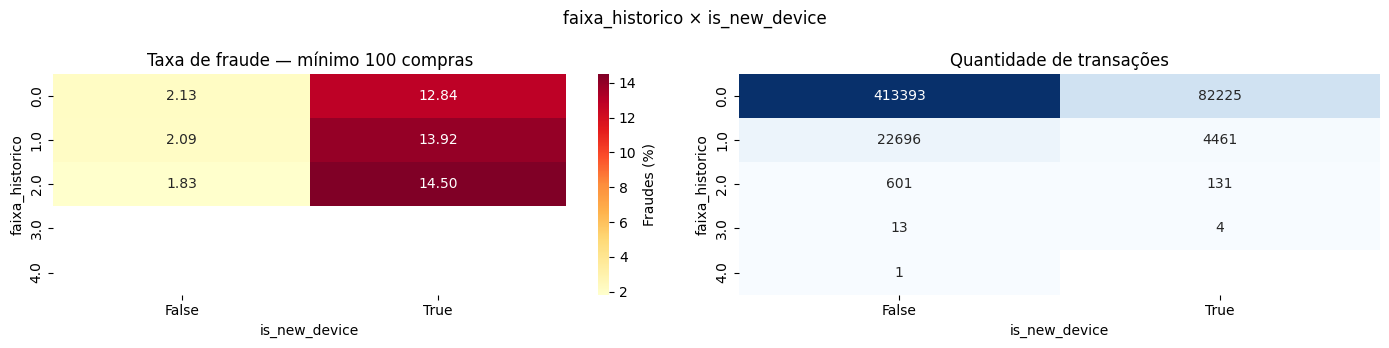

**Leitura descritiva:** maior taxa elegível em faixa_historico=2.0, is_new_device=True: **14.50%**, 19 fraudes em 131 compras (IC 95%: 9.49%–21.54%; lift 3.71× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**compras_ultimos_7d:** faixas descritivas cruzadas com dispositivo novo.

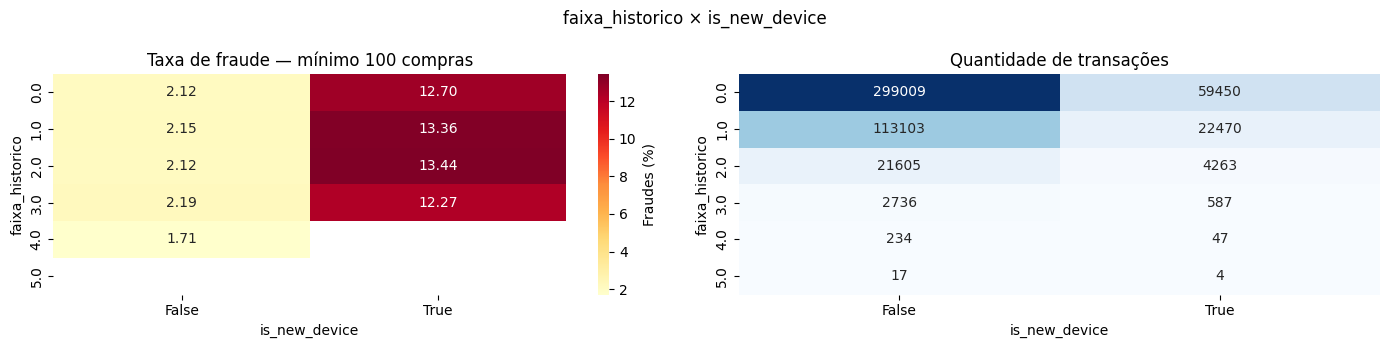

**Leitura descritiva:** maior taxa elegível em faixa_historico=2.0, is_new_device=True: **13.44%**, 573 fraudes em 4,263 compras (IC 95%: 12.45%–14.50%; lift 3.44× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**compras_ultimos_30d:** faixas descritivas cruzadas com dispositivo novo.

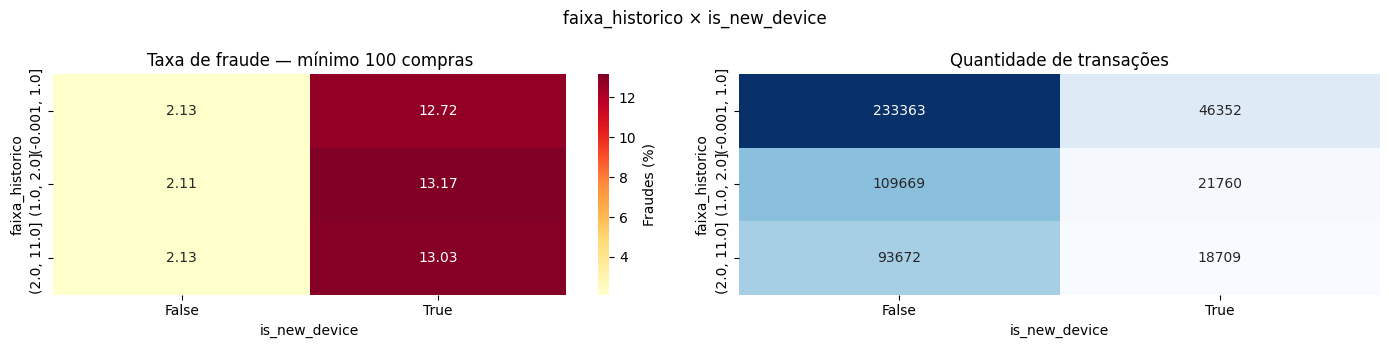

**Leitura descritiva:** maior taxa elegível em faixa_historico=(1.0, 2.0], is_new_device=True: **13.17%**, 2,865 fraudes em 21,760 compras (IC 95%: 12.72%–13.62%; lift 3.36× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**horas_desde_ultima_compra:** faixas descritivas cruzadas com dispositivo novo.

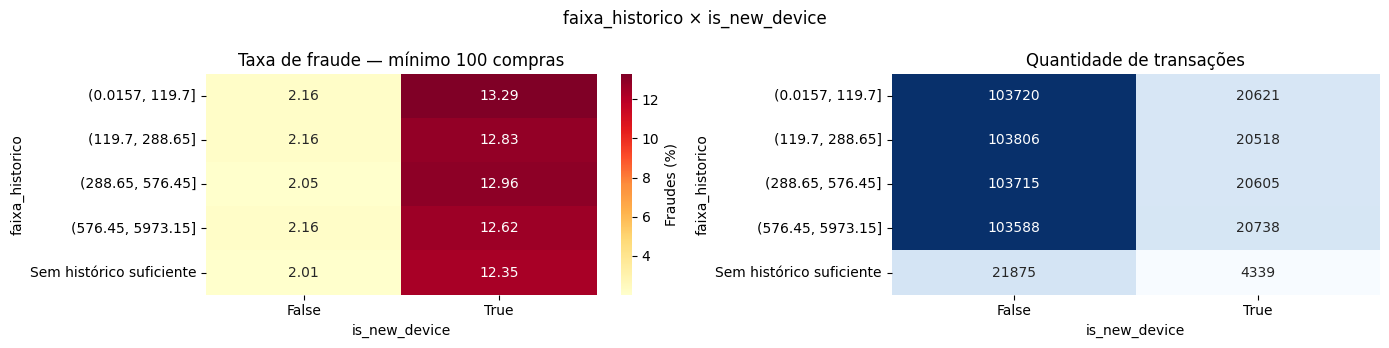

**Leitura descritiva:** maior taxa elegível em faixa_historico=(0.0157, 119.7], is_new_device=True: **13.29%**, 2,741 fraudes em 20,621 compras (IC 95%: 12.84%–13.76%; lift 3.40× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**valor_medio_ultimos_30d:** faixas descritivas cruzadas com dispositivo novo.

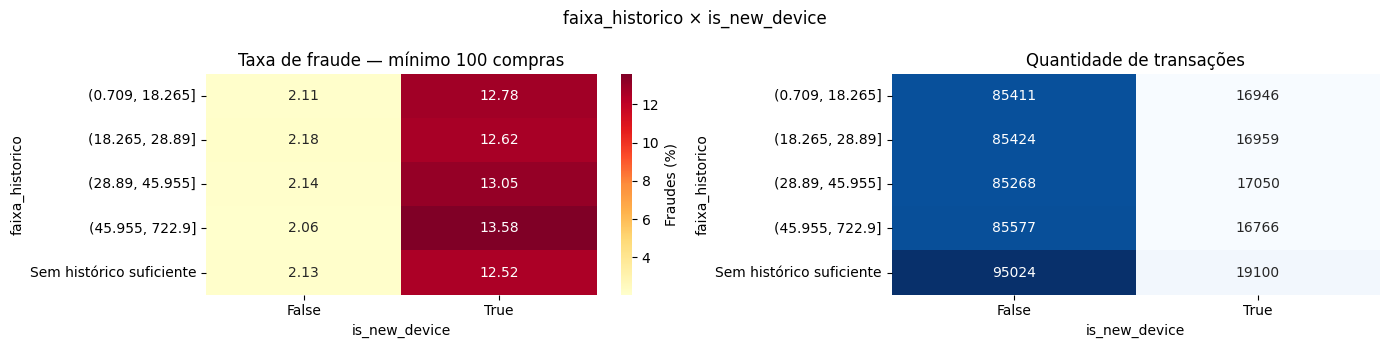

**Leitura descritiva:** maior taxa elegível em faixa_historico=(45.955, 722.9], is_new_device=True: **13.58%**, 2,276 fraudes em 16,766 compras (IC 95%: 13.06%–14.10%; lift 3.47× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**valor_desvio_padrao_ultimos_30d:** faixas descritivas cruzadas com dispositivo novo.

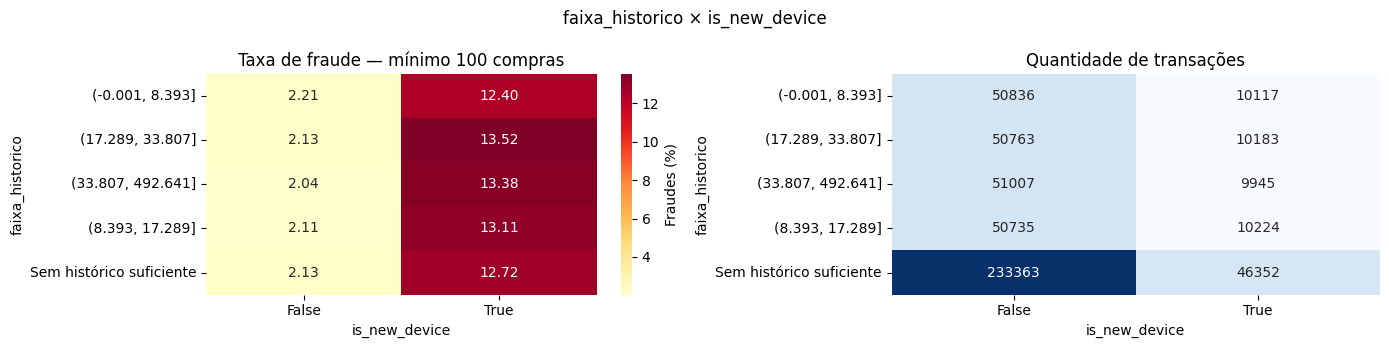

**Leitura descritiva:** maior taxa elegível em faixa_historico=(17.289, 33.807], is_new_device=True: **13.52%**, 1,377 fraudes em 10,183 compras (IC 95%: 12.87%–14.20%; lift 3.46× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**valor_diferenca_media_30d:** faixas descritivas cruzadas com dispositivo novo.

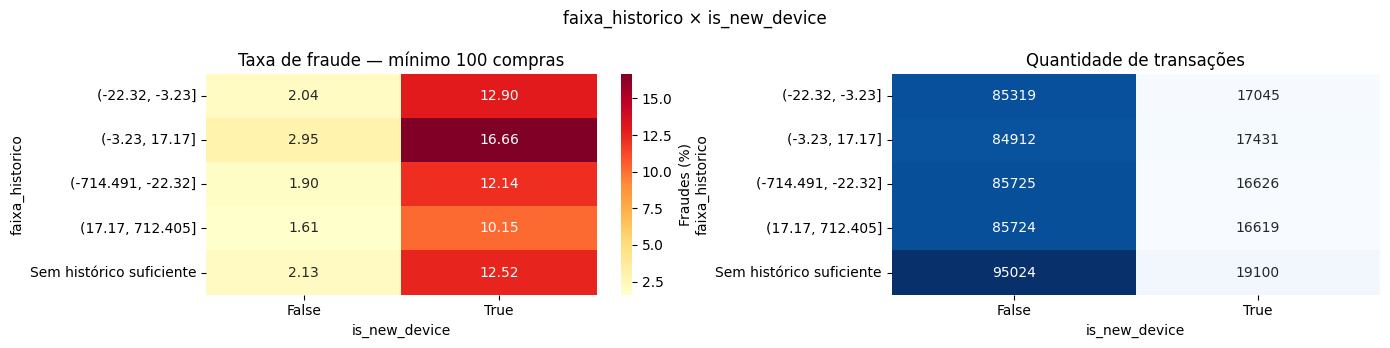

**Leitura descritiva:** maior taxa elegível em faixa_historico=(-3.23, 17.17], is_new_device=True: **16.66%**, 2,904 fraudes em 17,431 compras (IC 95%: 16.11%–17.22%; lift 4.26× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**valor_razao_media_30d:** faixas descritivas cruzadas com dispositivo novo.

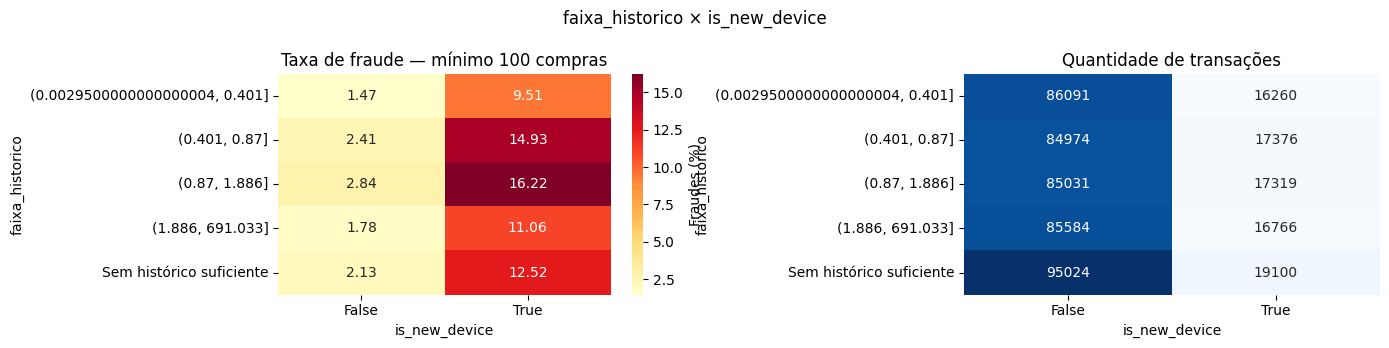

**Leitura descritiva:** maior taxa elegível em faixa_historico=(0.87, 1.886], is_new_device=True: **16.22%**, 2,810 fraudes em 17,319 compras (IC 95%: 15.68%–16.78%; lift 4.15× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

**sem_historico_anterior:** faixas descritivas cruzadas com dispositivo novo.

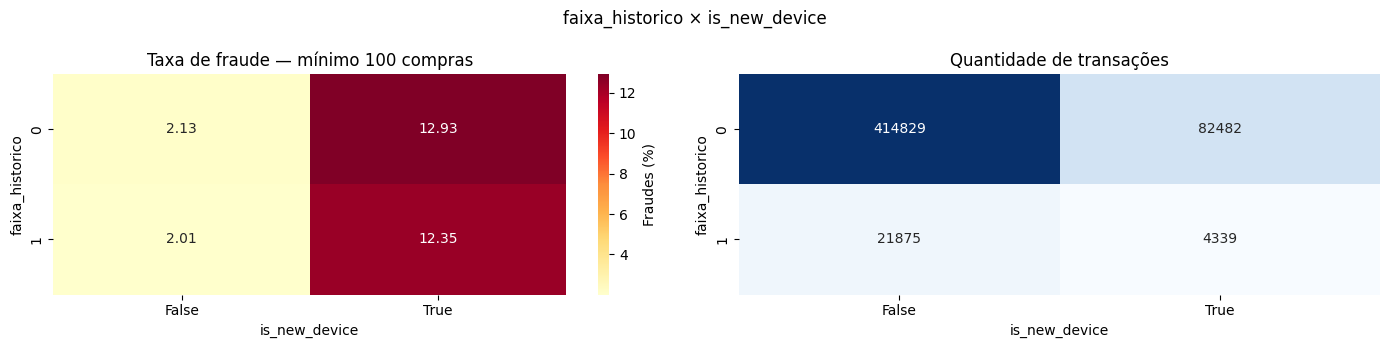

**Leitura descritiva:** maior taxa elegível em faixa_historico=0, is_new_device=True: **12.93%**, 10,663 fraudes em 82,482 compras (IC 95%: 12.70%–13.16%; lift 3.30× a taxa global). O cruzamento descreve associação; não demonstra causalidade nem ganho preditivo.

In [18]:
# Analyze behavioral features alongside device novelty and missing history.
# ---------------------------------------
analise_features_comportamentais = behavior_analysis(
    df_historical,
    BEHAVIOR_NUMERICAL_FEATURES + ['sem_historico_anterior'],
)


### Scope of this analysis and next steps

The tables identify risk combinations, feature coverage, and differences between segments. Association with the target does not guarantee incremental model value. When the new models are built, error analysis must use predictions outside the training set and report false positives, false negatives, precision, and recall by month and segment, with an explicit threshold. This section contains no model training or model error analysis.


## 5.1 — Training the new models

Logistic regression, HistGradientBoosting, Random Forest, and MLP are trained with all new features, without comparison against the previous version. The split remains random: 84% training, 8% validation, and 8% test. Validation guides decisions; test labels are excluded from selection.

The scaler, encoder, and imputer are fitted only on training data. Median imputation adds indicators for missing history. Logistic regression, HistGradientBoosting, and Random Forest use class balancing; MLP retains its original configuration without weights. Scores have not been calibrated as absolute probabilities.

The reproducible workflow is in `training_workflow.py`; models, transformers, indices, and predictions are persisted in `artifacts/training/`. To retrain, explicitly execute `run_training()`. The following cells load previously generated results without retraining.


In [22]:
# Load validation metrics, predictions, fitted preprocessing, and trained models.
# ---------------------------------------
metricas_validacao = pd.read_csv(ARTIFACTS / 'validation_metrics.csv')
previsoes_validacao = pd.read_csv(ARTIFACTS / 'validation_predictions.csv')
previsoes_teste = pd.read_csv(ARTIFACTS / 'test_predictions.csv')
preprocessador_treinado = joblib.load(ARTIFACTS / 'preprocessing.joblib')
modelos_treinados = {
    nome: joblib.load(ARTIFACTS / f'{nome}.joblib')
    for nome in metricas_validacao['model']
}
display(metricas_validacao)


,model,validation_roc_auc,validation_average_precision,reference_threshold,validation_precision,validation_recall,validation_f1,training_seconds
0,logistic_regression,0.895199,0.213200,0.5,0.140518,0.837706,0.240666,2.632200
1,hist_gradient_boosting,0.950127,0.467893,0.5,0.179837,0.941428,0.301986,9.156985
2,random_forest,0.938113,0.368130,0.5,0.403644,0.446004,0.423768,124.807164
3,mlp,0.949553,0.463353,0.5,0.632887,0.201952,0.306198,108.004602


### Validation ranking quality

Average precision and ROC-AUC describe score ranking. Precision, recall, and F1 in the table use 0.5 only as a descriptive reference. The operational threshold is determined by the budget rather than this fixed value.


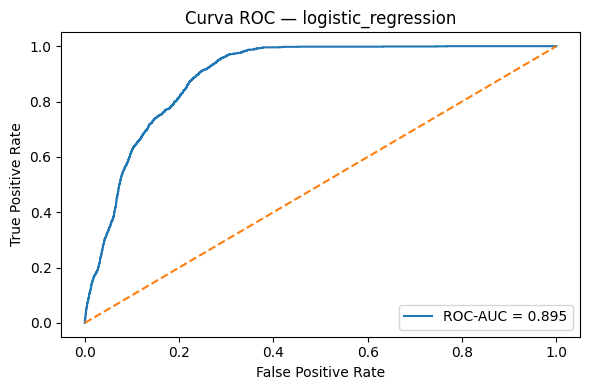

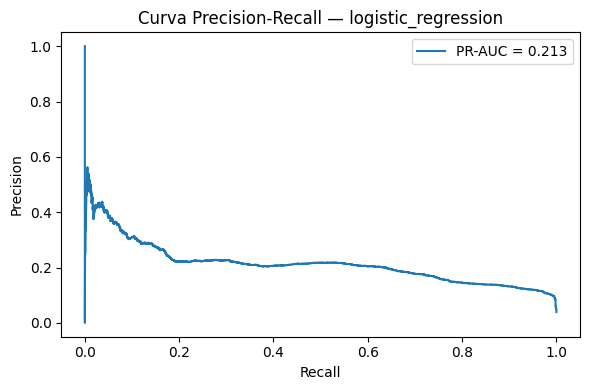

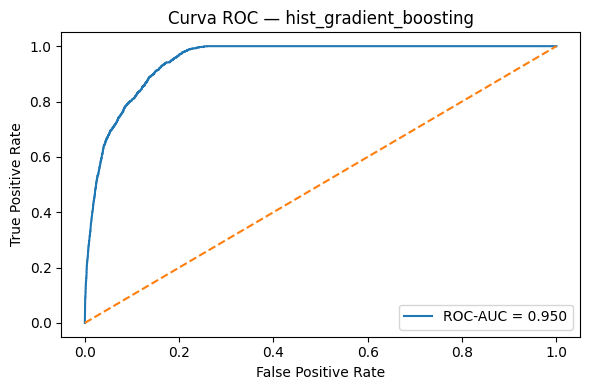

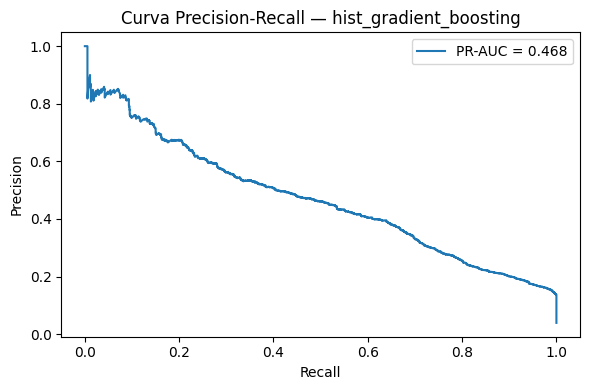

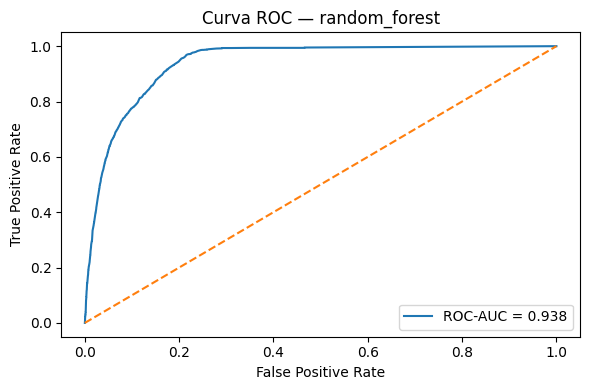

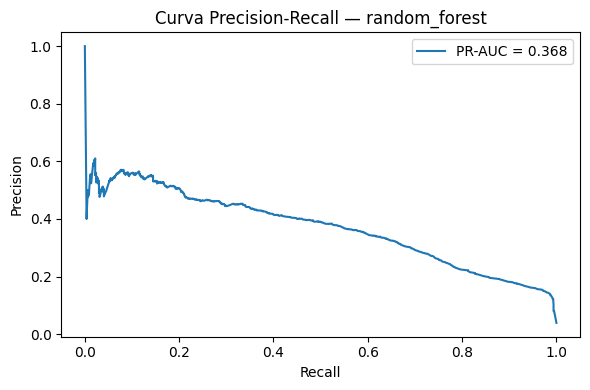

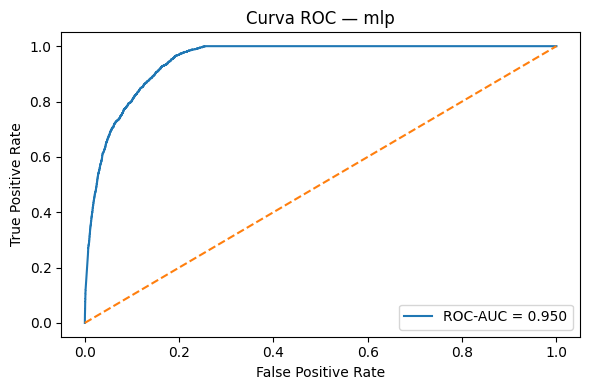

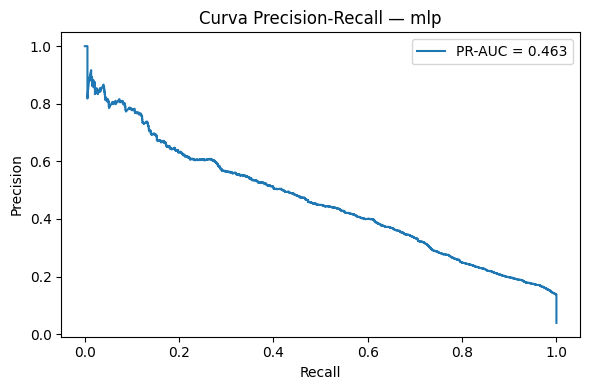

In [23]:
# Plot ROC and precision-recall curves for the validation predictions.
# ---------------------------------------
for nome in modelos_treinados:
    plot_roc_pr_curves(
        previsoes_validacao['y_true'], previsoes_validacao[nome], title=nome
    )


## 5.2 — Threshold under a verification cost constraint

This step selects a score threshold that respects the available alert-review budget. Score-based prioritization ensures that the number of reviewed alerts stays within the financial capacity defined by the budget.

Each reviewed alert costs **X Brazilian reais**, whether it is actual fraud or a false positive. A budget of **Y Brazilian reais per batch/period** allows at most **⌊Y/X⌋ reviews**. The `threshold_for_budget` function selects the highest scores without exceeding this capacity. Tied scores receive the same decision; if a tied group exceeds capacity, it is excluded and some budget may remain unused. An infinite threshold means no reviews.

The objective is to use capacity to prioritize the highest scores. This does not minimize financial losses: costs for undetected fraud and incorrect blocking were not provided. On labeled validation data, we measure how many fraud cases would be recovered within budget and select the model with the highest recovery (breaking ties by average precision and name).

**Enter the actual values below.** They must correspond to the evaluated batch; a monthly budget should not be applied in full to every segment or to a sample without adjusting its scale. No monetary values are assumed. A fixed threshold does not guarantee the cap for a future batch: the threshold is recalculated using each batch's scores without consulting its labels. This adjusts the review queue without updating the model.


### Capacity curves independent of X and Y

The following curves measure precision and recall as a function of review count. For any cost X, spending is `reviews × X`; allowed capacity is `floor(Y/X)`. An internal unit cost of 1 is used only to construct the normalized curve, without assuming an actual cost of R$ 1.


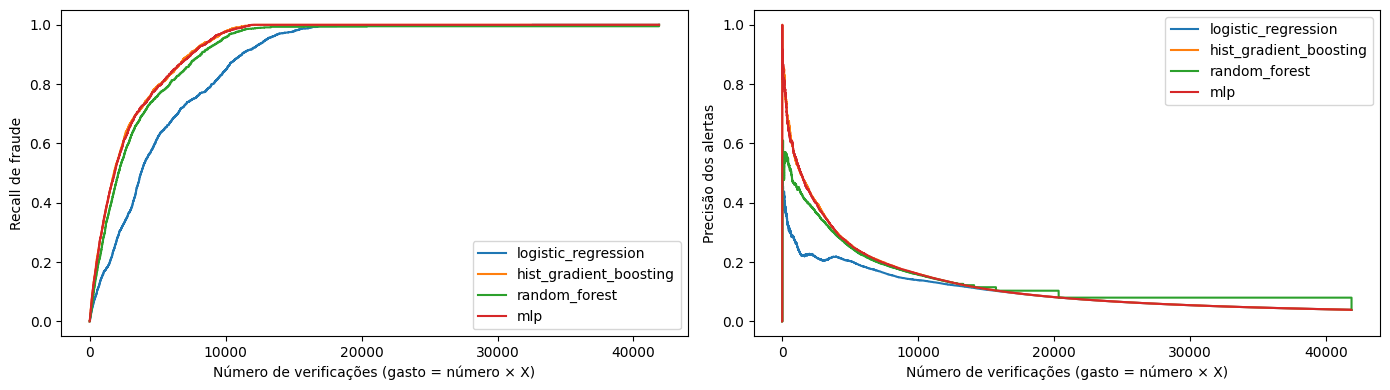

In [24]:
# Compare validation precision and recall across review capacities.
# ---------------------------------------
curvas_capacidade = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for nome in modelos_treinados:
    curva = cost_curve(previsoes_validacao['y_true'], previsoes_validacao[nome], verification_cost=1)
    curvas_capacidade[nome] = curva.drop(columns='verification_spend')
    axes[0].step(curva['reviews'], curva['recall'], where='post', label=nome)
    axes[1].step(curva['reviews'], curva['precision'], where='post', label=nome)
for ax in axes:
    ax.set_xlabel('Number of reviews (spending = count × X)')
    ax.legend()
axes[0].set_ylabel('Fraud recall')
axes[1].set_ylabel('Alert precision')
fig.tight_layout()
plt.show()


In [41]:
# Configure the review cost, batch budget, and budget period.
# ---------------------------------------
CUSTO_VERIFICACAO_REAIS = 4.0  # X: Brazilian reais per reviewed alert
ORCAMENTO_LOTE_REAIS = 10000     # Y: Brazilian reais available for the evaluated batch
PERIODO_ORCAMENTO = 1        # Example: month; document the batch scale

orcamento_configurado = (
    CUSTO_VERIFICACAO_REAIS is not None
    and ORCAMENTO_LOTE_REAIS is not None
    and PERIODO_ORCAMENTO is not None
)
if not orcamento_configurado:
    display(Markdown('**Pending:** provide X, Y, and the period to calculate the operational threshold.'))


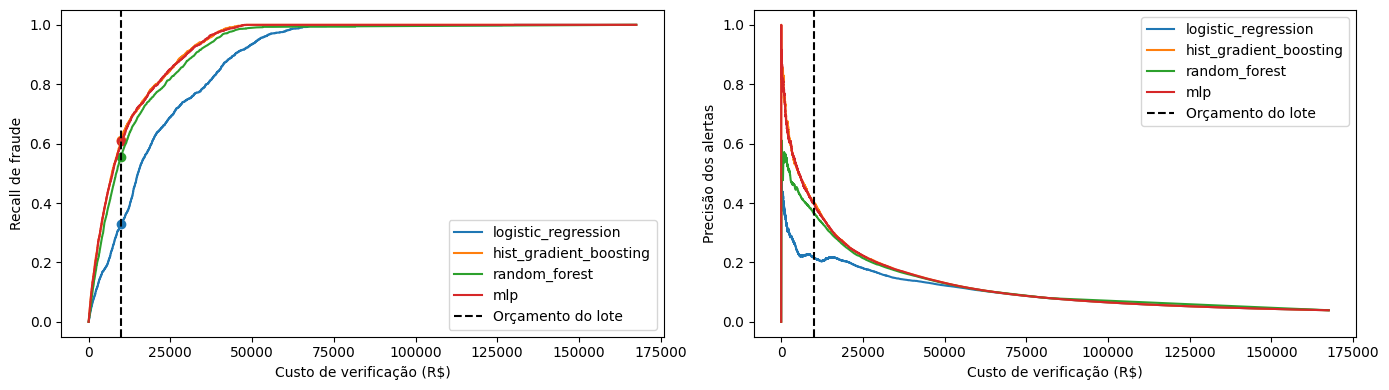

,model,threshold,reviews,spent,remaining_budget,true_positive,precision,recall,average_precision
1,hist_gradient_boosting,0.855291,2500,10000.0,0.0,1001,0.400400,0.610738,0.467893
3,mlp,0.203341,2500,10000.0,0.0,998,0.399200,0.608908,0.463353
2,random_forest,0.403833,2485,9940.0,60.0,909,0.365795,0.554606,0.368130
0,logistic_regression,0.889728,2500,10000.0,0.0,539,0.215600,0.328859,0.213200


In [42]:
# Evaluate budget-constrained validation results and select the model.
# ---------------------------------------
if orcamento_configurado:
    curvas_custo = {}
    linhas = []
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for nome in modelos_treinados:
        scores = previsoes_validacao[nome]
        decisao = threshold_for_budget(scores, CUSTO_VERIFICACAO_REAIS, ORCAMENTO_LOTE_REAIS)
        curva = cost_curve(previsoes_validacao['y_true'], scores, CUSTO_VERIFICACAO_REAIS)
        curvas_custo[nome] = curva
        verdade = previsoes_validacao['y_true'].to_numpy().astype(bool)
        tp = int((decisao['selected'] & verdade).sum())
        linhas.append({
            'model': nome, 'threshold': decisao['threshold'],
            'reviews': decisao['reviews'], 'spent': decisao['spent'],
            'remaining_budget': decisao['remaining_budget'], 'true_positive': tp,
            'precision': tp / max(decisao['reviews'], 1),
            'recall': tp / max(int(verdade.sum()), 1),
            'average_precision': float(metricas_validacao.set_index('model').loc[nome, 'validation_average_precision']),
        })
        axes[0].plot(curva['verification_spend'], curva['recall'], label=nome)
        axes[1].plot(curva['verification_spend'], curva['precision'], label=nome)
        axes[0].scatter([decisao['spent']], [linhas[-1]['recall']])
    for ax in axes:
        ax.axvline(float(ORCAMENTO_LOTE_REAIS), color='black', linestyle='--', label='Batch budget')
        ax.set_xlabel('Verification cost (R$)')
        ax.legend()
    axes[0].set_ylabel('Fraud recall')
    axes[1].set_ylabel('Alert precision')
    fig.tight_layout()
    plt.show()
    resumo_orcamento = pd.DataFrame(linhas).sort_values(
        ['true_positive', 'average_precision', 'model'], ascending=[False, False, True]
    )
    display(resumo_orcamento)
    modelo_escolhido = resumo_orcamento.iloc[0]['model']
    resumo_orcamento.to_csv(ARTIFACTS / 'validation_budget_metrics.csv', index=False)


### Final evaluation and errors by month and segment

The model is selected on validation data. On the test set, the threshold is recalculated only from scores to respect the new batch's capacity; labels are used exclusively to measure results. The budget is global for this batch, without independent allocation by month or segment.


,threshold,capacity,reviews,verification_cost,budget,spent,remaining_budget
0,0.853015,2500,2500,4.0,10000.0,10000.0,0.0


,transacoes,fraudes,alertas,tp,fp,fn,precision,recall,custo_verificacao
month,,,,,,,,,
1,3557,132,214,77,137,55,0.359813,0.583333,856.0
2,3242,116,169,68,101,48,0.402367,0.586207,676.0
3,3602,152,218,105,113,47,0.481651,0.690789,872.0
4,3386,125,199,72,127,53,0.361809,0.576000,796.0
5,3516,147,218,87,131,60,0.399083,0.591837,872.0
6,3436,127,206,79,127,48,0.383495,0.622047,824.0
7,3551,130,182,82,100,48,0.450549,0.630769,728.0
8,3502,121,174,72,102,49,0.413793,0.595041,696.0
9,3530,130,182,74,108,56,0.406593,0.569231,728.0


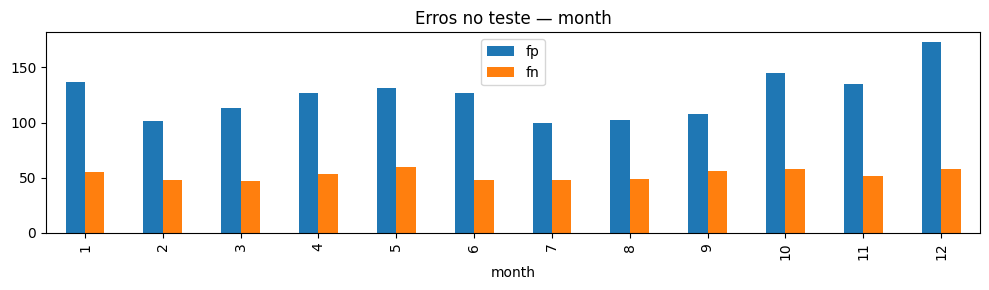

,transacoes,fraudes,alertas,tp,fp,fn,precision,recall,custo_verificacao
cidade,,,,,,,,,
Belo Horizonte,6067,224,337,139,198,85,0.412463,0.620536,1348.0
Curitiba,5945,217,321,119,202,98,0.370717,0.548387,1284.0
Porto Alegre,5895,209,362,132,230,77,0.364641,0.631579,1448.0
Recife,5907,164,210,82,128,82,0.390476,0.500000,840.0
Rio de Janeiro,5894,345,537,220,317,125,0.409683,0.637681,2148.0
Salvador,6072,133,218,77,141,56,0.353211,0.578947,872.0
São Paulo,6102,341,515,232,283,109,0.450485,0.680352,2060.0


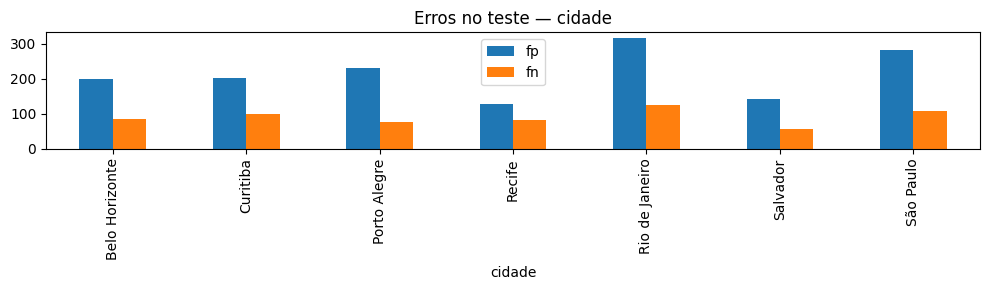

,transacoes,fraudes,alertas,tp,fp,fn,precision,recall,custo_verificacao
tipo_estabelecimento,,,,,,,,,
E-commerce,8392,269,417,174,243,95,0.417266,0.646840,1668.0
Food & Beverage,8399,548,892,336,556,212,0.376682,0.613139,3568.0
Fuel,4156,309,489,230,259,79,0.470348,0.744337,1956.0
Pharmacy,4267,100,122,44,78,56,0.360656,0.440000,488.0
Retail,8314,201,287,108,179,93,0.376307,0.537313,1148.0
Supermarket,8354,206,293,109,184,97,0.372014,0.529126,1172.0


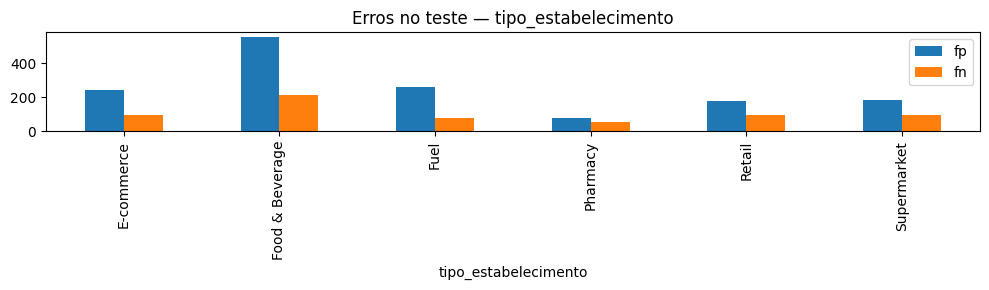

,transacoes,fraudes,alertas,tp,fp,fn,precision,recall,custo_verificacao
is_new_device,,,,,,,,,
False,35050,711,495,144,351,567,0.290909,0.202532,1980.0
True,6832,922,2005,857,1148,65,0.427431,0.929501,8020.0


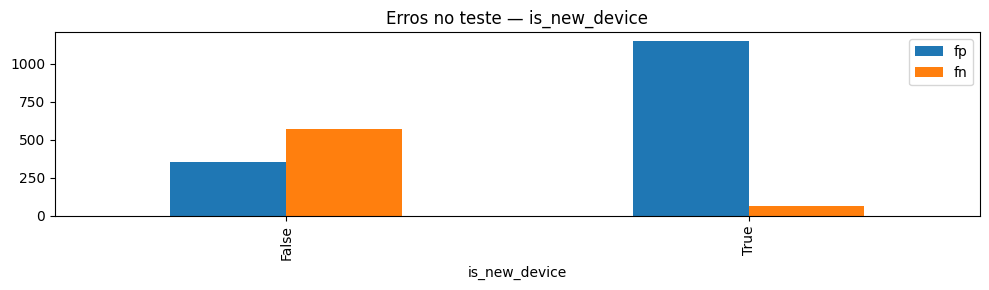

In [43]:
# Evaluate the selected model and summarize test errors by segment.
# ---------------------------------------
if orcamento_configurado:
    decisao_teste = threshold_for_budget(
        previsoes_teste[modelo_escolhido], CUSTO_VERIFICACAO_REAIS, ORCAMENTO_LOTE_REAIS
    )
    erros_teste = previsoes_teste.copy()
    erros_teste['selected'] = decisao_teste['selected']
    verdadeiro = erros_teste['y_true'].astype(bool)
    erros_teste['tp'] = erros_teste['selected'] & verdadeiro
    erros_teste['fp'] = erros_teste['selected'] & ~verdadeiro
    erros_teste['fn'] = ~erros_teste['selected'] & verdadeiro
    display(pd.DataFrame([{
        chave: valor for chave, valor in decisao_teste.items() if chave != 'selected'
    }]))
    for segmento in ['month', 'cidade', 'tipo_estabelecimento', 'is_new_device']:
        tabela = erros_teste.groupby(segmento, dropna=False).agg(
            transacoes=('y_true', 'size'), fraudes=('y_true', 'sum'),
            alertas=('selected', 'sum'), tp=('tp', 'sum'), fp=('fp', 'sum'), fn=('fn', 'sum')
        )
        tabela['precision'] = tabela['tp'].div(tabela['alertas'].replace(0, np.nan))
        tabela['recall'] = tabela['tp'].div(tabela['fraudes'].replace(0, np.nan))
        tabela['custo_verificacao'] = tabela['alertas'] * float(CUSTO_VERIFICACAO_REAIS)
        display(tabela)
        tabela[['fp', 'fn']].plot.bar(figsize=(10, 3), title=f'Test errors — {segmento}')
        plt.tight_layout()
        plt.show()
    erros_teste.to_csv(ARTIFACTS / 'test_budget_predictions.csv', index=False)
